
# STRATUM — XGBoost Regression

## Phase 3 — Step 3.4

### Objective

Develop gradient-boosted regression models for
semiconductor mean film thickness prediction.

### Research Questions

1. Can gradient boosting outperform Random Forest?
2. How do learning rate, depth and regularisation
   affect chronological validation performance?
3. Does explicit equipment metadata improve predictions?
4. Does native missing-value handling outperform
   median imputation with missingness indicators?
5. Can XGBoost produce reliable and physically
   plausible predictions?
6. How does model complexity affect predictive
   performance and computational cost?

### Reference Benchmarks

Equipment Mean:
- MAE: 1.995479
- RMSE: 2.444380
- R2: -0.001596

Bounded Ridge:
- MAE: 1.267788
- RMSE: 1.673137
- R2: 0.530735

Random Forest:
- MAE: 1.158247
- RMSE: 1.529514
- R2: 0.607841

### Evaluation Protocol

- Reuse the fixed chronological and lot-aware partitions.
- Fit all models and preprocessing on training data.
- Compare models using validation data only.
- Evaluate prediction plausibility and large errors.
- Preserve all validation observations.
- Reserve final testing for Step 3.8.

### Important Limitations

XGBoost predictions are not inherently restricted
to the training target range.

Native missing-value handling does not guarantee
robustness to unfamiliar manufacturing conditions.

Feature importance does not establish causality.

In [1]:

# STEP 3.4.5 - Imports

from pathlib import Path
import sys
import json
import hashlib
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import xgboost

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (current_dir / "ml" / "xgboost_models.py").exists():

    project_root = current_dir

elif (
    current_dir.parent
    / "ml"
    / "xgboost_models.py"
).exists():

    project_root = current_dir.parent

else:

    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml.data_split import chronological_lot_split

from ml.preprocessing import get_feature_columns

from ml.evaluation import (
    evaluate_regression,
    calculate_mae_improvement,
)

from ml.xgboost_models import (
    build_xgboost_model,
    extract_xgboost_feature_importance,
)

print("STRATUM - XGBoost Regression")
print("Python version:", sys.version.split()[0])
print("Scikit-learn version:", sklearn.__version__)
print("XGBoost version:", xgboost.__version__)

print("\nAll modules imported successfully!")

STRATUM - XGBoost Regression
Python version: 3.14.3
Scikit-learn version: 1.9.1
XGBoost version: 3.4.1

All modules imported successfully!


## 1. Dataset and Split Reproducibility

Verify the dataset fingerprint, reproduce the
chronological partitions, and confirm the expected
APC feature schema.

In [2]:

# STEP 3.4.6 - Verify dataset and partitions

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest = json.loads(
    (
        project_root
        / "docs"
        / "split_manifest.json"
    ).read_text(encoding="utf-8")
)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert (
    current_sha256 == manifest["dataset_sha256"]
), "Dataset fingerprint mismatch."

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

assert df.shape == (5208, 178)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,
        test_fraction=manifest["test_fraction"],
        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert split_info == manifest["split_summary"]

apc_features, feature_columns = (
    get_feature_columns(df)
)

assert (
    apc_features == manifest["numeric_apc_features"]
)

print("Dataset fingerprint: VERIFIED")
print("Chronological partitions: VERIFIED")
print("APC feature schema: VERIFIED")

print("\nTraining records:", len(train_df))
print("Validation records:", len(val_df))
print("Reserved test records:", len(test_df))

Dataset fingerprint: VERIFIED
Chronological partitions: VERIFIED
APC feature schema: VERIFIED

Training records: 3331
Validation records: 834
Reserved test records: 1042


## 2. Reference Benchmark Verification

Load the historical baseline, bounded Ridge,
and Random Forest experiment results.

Ensure that all reference models use the same
dataset, prediction target and validation partition.

In [3]:

# STEP 3.4.7 - Load reference benchmarks

results_dir = project_root / "ml" / "results"

baseline_experiment = json.loads(
    (
        results_dir / "thickness_baselines.json"
    ).read_text(encoding="utf-8")
)

ridge_experiment = json.loads(
    (
        results_dir
        / "thickness_linear_robustness.json"
    ).read_text(encoding="utf-8")
)

forest_experiment = json.loads(
    (
        results_dir / "thickness_random_forest.json"
    ).read_text(encoding="utf-8")
)

for experiment in [
    baseline_experiment,
    ridge_experiment,
    forest_experiment,
]:

    assert (
        experiment["dataset_sha256"]
        == current_sha256
    )

    assert (
        experiment["evaluation_partition"]
        == "validation"
    )

    assert (
        experiment["target"]
        == "mean_thickness"
    )

    assert (
        experiment["training_records"]
        == len(train_df)
    )

    assert (
        experiment["validation_records"]
        == len(val_df)
    )

BASELINE_MAE = float(
    baseline_experiment["best_baseline_mae"]
)

RIDGE_MAE = float(
    ridge_experiment["best_model_mae"]
)

FOREST_MAE = float(
    forest_experiment["best_model_mae"]
)

FOREST_RMSE = float(
    forest_experiment["best_model_rmse"]
)

FOREST_R2 = float(
    forest_experiment["best_model_r2"]
)

print("Equipment Mean MAE:", round(BASELINE_MAE, 6))
print("Bounded Ridge MAE:", round(RIDGE_MAE, 6))
print("Random Forest MAE:", round(FOREST_MAE, 6))
print("Random Forest RMSE:", round(FOREST_RMSE, 6))
print("Random Forest R2:", round(FOREST_R2, 6))

print("\nReference benchmarks verified!")

Equipment Mean MAE: 1.995479
Bounded Ridge MAE: 1.267788
Random Forest MAE: 1.158247
Random Forest RMSE: 1.529514
Random Forest R2: 0.607841

Reference benchmarks verified!


## 3. Model Input Configuration

Compare APC-only and APC-plus-equipment inputs.

Prepare identical training and validation targets
for all XGBoost experiments.

The final test targets remain reserved.

In [4]:

# STEP 3.4.8 - Prepare input configurations

TARGET = "mean_thickness"

feature_configurations = {
    "APC Only": {
        "columns": apc_features,
        "include_equipment": False,
    },
    "APC + Equipment": {
        "columns": feature_columns,
        "include_equipment": True,
    },
}

y_train = train_df[TARGET].copy()
y_val = val_df[TARGET].copy()

assert np.isfinite(y_train).all()
assert np.isfinite(y_val).all()

assert (y_train > 0).all()
assert (y_val > 0).all()

for config_name, config in (
    feature_configurations.items()
):

    columns = config["columns"]

    assert TARGET not in columns
    assert "mean_resistance" not in columns

    print(f"\n{config_name}")

    print(
        "Training shape:",
        train_df[columns].shape
    )

    print(
        "Validation shape:",
        val_df[columns].shape
    )

print(
    "\nTraining target range:",
    float(y_train.min()),
    "to",
    float(y_train.max()),
)


APC Only
Training shape: (3331, 110)
Validation shape: (834, 110)

APC + Equipment
Training shape: (3331, 111)
Validation shape: (834, 111)

Training target range: 141.9620738610548 to 163.64180029940047


## 4. Gradient Boosting Experimental Design

Evaluate four predefined XGBoost configurations
using two feature configurations.

The primary experiments use median imputation
with missingness indicators.

Native missing-value handling will be evaluated
separately using matching hyperparameters.

In [5]:

# STEP 3.4.9 - Experimental configurations

boosting_configurations = [
    {
        "name": "XGB-1 Reference",
        "n_estimators": 300,
        "max_depth": 6,
        "learning_rate": 0.1,
        "min_child_weight": 1,
        "reg_alpha": 0.0,
        "reg_lambda": 1.0,
    },
    {
        "name": "XGB-2 Shallow",
        "n_estimators": 300,
        "max_depth": 3,
        "learning_rate": 0.1,
        "min_child_weight": 1,
        "reg_alpha": 0.0,
        "reg_lambda": 1.0,
    },
    {
        "name": "XGB-3 Regularised",
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "reg_alpha": 0.1,
        "reg_lambda": 5.0,
    },
    {
        "name": "XGB-4 Slow Boosting",
        "n_estimators": 600,
        "max_depth": 4,
        "learning_rate": 0.025,
        "min_child_weight": 5,
        "reg_alpha": 0.1,
        "reg_lambda": 5.0,
    },
]

RANDOM_STATE = 42

N_JOBS = -1

SUBSAMPLE = 0.8

COLSAMPLE = 0.8

display(
    pd.DataFrame(boosting_configurations)
)

print(
    "Primary experiments:",
    len(boosting_configurations)
    * len(feature_configurations)
)

,name,n_estimators,max_depth,learning_rate,min_child_weight,reg_alpha,reg_lambda
0,XGB-1 Reference,300,6,0.100,1,0.0,1.0
1,XGB-2 Shallow,300,3,0.100,1,0.0,1.0
2,XGB-3 Regularised,300,4,0.050,5,0.1,5.0
3,XGB-4 Slow Boosting,600,4,0.025,5,0.1,5.0


Primary experiments: 8


## 5. XGBoost Experiment Execution

Implement a common training and evaluation workflow
for all gradient-boosted regression experiments.

Record training and validation metrics, prediction
validity, maximum error and computational cost.

In [6]:

# STEP 3.4.10 - Reusable experiment function

trained_xgb_models = {}

validation_predictions = {}

training_predictions = {}


def run_xgb_experiment(
    feature_name,
    feature_config,
    boosting_config,
    missing_strategy="median",
):

    columns = feature_config["columns"]

    X_train = train_df[columns]
    X_val = val_df[columns]

    model_name = (
        f"{boosting_config['name']} "
        f"({feature_name}, {missing_strategy})"
    )

    model_parameters = {
        key: value
        for key, value in boosting_config.items()
        if key != "name"
    }

    pipeline = build_xgboost_model(
        numeric_features=apc_features,
        include_equipment=feature_config[
            "include_equipment"
        ],
        missing_strategy=missing_strategy,
        subsample=SUBSAMPLE,
        colsample_bytree=COLSAMPLE,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        **model_parameters,
    )

    start = time.perf_counter()

    pipeline.fit(X_train, y_train)

    training_time = time.perf_counter() - start

    train_pred = pipeline.predict(X_train)

    start = time.perf_counter()

    val_pred = pipeline.predict(X_val)

    prediction_time = time.perf_counter() - start

    assert len(val_pred) == len(y_val)

    assert np.isfinite(train_pred).all()
    assert np.isfinite(val_pred).all()

    train_metrics = evaluate_regression(
        y_train,
        train_pred,
    )

    val_metrics = evaluate_regression(
        y_val,
        val_pred,
    )

    absolute_errors = np.abs(
        y_val.to_numpy() - val_pred
    )

    outside_training_range = (
        (val_pred < y_train.min())
        |
        (val_pred > y_train.max())
    )

    result = {
        "Model": model_name,
        "Algorithm": "XGBoost",
        "Configuration": feature_name,
        "Boosting Configuration": boosting_config[
            "name"
        ],
        "Missing Strategy": missing_strategy,

        **model_parameters,

        "Training MAE": train_metrics["MAE"],
        "Training RMSE": train_metrics["RMSE"],
        "Training R2": train_metrics["R2"],

        **val_metrics,

        "Generalisation Gap": (
            val_metrics["MAE"]
            - train_metrics["MAE"]
        ),

        "Maximum Absolute Error": float(
            absolute_errors.max()
        ),

        "P95 Absolute Error": float(
            np.quantile(absolute_errors, 0.95)
        ),

        "Non-Positive Predictions": int(
            (val_pred <= 0).sum()
        ),

        "Outside Training Target Range": int(
            outside_training_range.sum()
        ),

        "Training Time (s)": training_time,

        "Validation Prediction Time (s)": (
            prediction_time
        ),

        "MAE Improvement vs Baseline (%)": (
            calculate_mae_improvement(
                BASELINE_MAE,
                val_metrics["MAE"],
            )
        ),

        "MAE Improvement vs Ridge (%)": (
            calculate_mae_improvement(
                RIDGE_MAE,
                val_metrics["MAE"],
            )
        ),

        "MAE Improvement vs Forest (%)": (
            calculate_mae_improvement(
                FOREST_MAE,
                val_metrics["MAE"],
            )
        ),
    }

    trained_xgb_models[model_name] = pipeline

    validation_predictions[model_name] = val_pred

    training_predictions[model_name] = train_pred

    print(
        f"{model_name}\n"
        f"Training MAE: {train_metrics['MAE']:.6f}\n"
        f"Validation MAE: {val_metrics['MAE']:.6f}\n"
        f"Validation RMSE: {val_metrics['RMSE']:.6f}\n"
        f"Validation R2: {val_metrics['R2']:.6f}\n"
        f"Training time: {training_time:.3f}s\n",
        flush=True,
    )

    return result

In [7]:

# STEP 3.4.11 - Train primary XGBoost models

primary_results = []

experiment_number = 0

total_primary_experiments = (
    len(feature_configurations)
    * len(boosting_configurations)
)

for feature_name, feature_config in (
    feature_configurations.items()
):

    for boosting_config in boosting_configurations:

        experiment_number += 1

        print(
            f"[{experiment_number}/"
            f"{total_primary_experiments}]",
            flush=True,
        )

        result = run_xgb_experiment(
            feature_name=feature_name,
            feature_config=feature_config,
            boosting_config=boosting_config,
            missing_strategy="median",
        )

        primary_results.append(result)

primary_results_df = (
    pd.DataFrame(primary_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    primary_results_df.round(6)
)

print("\nAll eight primary experiments completed.")

[1/8]
XGB-1 Reference (APC Only, median)
Training MAE: 0.128818
Validation MAE: 1.116893
Validation RMSE: 1.482235
Validation R2: 0.631711
Training time: 4.670s

[2/8]
XGB-2 Shallow (APC Only, median)
Training MAE: 0.704753
Validation MAE: 1.110232
Validation RMSE: 1.477216
Validation R2: 0.634201
Training time: 0.751s

[3/8]
XGB-3 Regularised (APC Only, median)
Training MAE: 0.729265
Validation MAE: 1.099118
Validation RMSE: 1.466369
Validation R2: 0.639553
Training time: 1.254s

[4/8]
XGB-4 Slow Boosting (APC Only, median)
Training MAE: 0.716879
Validation MAE: 1.090297
Validation RMSE: 1.460278
Validation R2: 0.642541
Training time: 2.076s

[5/8]
XGB-1 Reference (APC + Equipment, median)
Training MAE: 0.127864
Validation MAE: 1.105670
Validation RMSE: 1.495916
Validation R2: 0.624881
Training time: 2.591s

[6/8]
XGB-2 Shallow (APC + Equipment, median)
Training MAE: 0.695691
Validation MAE: 1.086421
Validation RMSE: 1.456615
Validation R2: 0.644332
Training time: 1.043s

[7/8]
XGB-3 

,Model,Algorithm,Configuration,Boosting Configuration,Missing Strategy,n_estimators,max_depth,learning_rate,min_child_weight,reg_alpha,...,Generalisation Gap,Maximum Absolute Error,P95 Absolute Error,Non-Positive Predictions,Outside Training Target Range,Training Time (s),Validation Prediction Time (s),MAE Improvement vs Baseline (%),MAE Improvement vs Ridge (%),MAE Improvement vs Forest (%)
0,"XGB-4 Slow Boosting (APC + Equipment, median)",XGBoost,APC + Equipment,XGB-4 Slow Boosting,median,600,4,0.025,5,0.1,...,0.360903,6.107028,3.093984,0,0,2.284096,0.014653,45.924634,14.886190,6.836556
1,"XGB-2 Shallow (APC + Equipment, median)",XGBoost,APC + Equipment,XGB-2 Shallow,median,300,3,0.100,1,0.0,...,0.390730,6.032026,3.069343,0,0,1.042827,0.015104,45.555876,14.305772,6.201245
2,"XGB-4 Slow Boosting (APC Only, median)",XGBoost,APC Only,XGB-4 Slow Boosting,median,600,4,0.025,5,0.1,...,0.373418,5.959079,3.045585,0,0,2.075858,0.011617,45.361638,14.000044,5.866602
3,"XGB-3 Regularised (APC + Equipment, median)",XGBoost,APC + Equipment,XGB-3 Regularised,median,300,4,0.050,5,0.1,...,0.370177,6.067981,3.066549,0,0,1.117134,0.013174,45.345258,13.974262,5.838382
4,"XGB-3 Regularised (APC Only, median)",XGBoost,APC Only,XGB-3 Regularised,median,300,4,0.050,5,0.1,...,0.369852,6.368116,3.048955,0,0,1.254499,0.010906,44.919597,13.304279,5.105035
5,"XGB-1 Reference (APC + Equipment, median)",XGBoost,APC + Equipment,XGB-1 Reference,median,300,6,0.100,1,0.0,...,0.977807,5.927603,3.064362,0,0,2.591382,0.016645,44.591230,12.787433,4.539309
6,"XGB-2 Shallow (APC Only, median)",XGBoost,APC Only,XGB-2 Shallow,median,300,3,0.100,1,0.0,...,0.405479,6.131900,3.110519,0,0,0.750506,0.010829,44.362623,12.427610,4.145455
7,"XGB-1 Reference (APC Only, median)",XGBoost,APC Only,XGB-1 Reference,median,300,6,0.100,1,0.0,...,0.988075,6.280048,3.042714,0,0,4.670031,0.012689,44.028836,11.902233,3.570391



All eight primary experiments completed.


## 6. Missing-Value Strategy Ablation

For each input configuration, select the
lowest-MAE eligible median-imputed XGBoost model.

Repeat the experiment using identical boosting
hyperparameters but native missing-value handling.

This compares two preprocessing strategies:
- Median imputation with missingness indicators.
- Native missing-value routing without indicators.

The comparison is exploratory because the reference
hyperparameters were selected using validation data.

In [8]:

# STEP 3.4.12 - Native missing-value comparison

native_results = []

for feature_name, feature_config in (
    feature_configurations.items()
):

    eligible_primary = primary_results_df.loc[
        (
            primary_results_df["Configuration"]
            == feature_name
        )
        &
        (
            primary_results_df[
                "Non-Positive Predictions"
            ] == 0
        )
    ]

    if eligible_primary.empty:

        raise ValueError(
            f"No eligible primary model for "
            f"{feature_name}"
        )

    reference_row = (
        eligible_primary
        .sort_values("MAE")
        .iloc[0]
    )

    reference_config = next(
        config
        for config in boosting_configurations
        if config["name"]
        == reference_row["Boosting Configuration"]
    )

    result = run_xgb_experiment(
        feature_name=feature_name,
        feature_config=feature_config,
        boosting_config=reference_config,
        missing_strategy="native",
    )

    native_results.append(result)

native_results_df = pd.DataFrame(
    native_results
)

all_results_df = (
    pd.concat(
        [
            primary_results_df,
            native_results_df,
        ],
        ignore_index=True,
    )
    .sort_values("MAE")
    .reset_index(drop=True)
)

print(
    "Total XGBoost experiments:",
    len(all_results_df)
)

display(
    all_results_df.round(6)
)


XGB-4 Slow Boosting (APC Only, native)
Training MAE: 0.707361
Validation MAE: 1.100808
Validation RMSE: 1.472487
Validation R2: 0.636539
Training time: 2.211s

XGB-4 Slow Boosting (APC + Equipment, native)
Training MAE: 0.706630
Validation MAE: 1.085851
Validation RMSE: 1.461776
Validation R2: 0.641808
Training time: 1.890s

Total XGBoost experiments: 10


,Model,Algorithm,Configuration,Boosting Configuration,Missing Strategy,n_estimators,max_depth,learning_rate,min_child_weight,reg_alpha,...,Generalisation Gap,Maximum Absolute Error,P95 Absolute Error,Non-Positive Predictions,Outside Training Target Range,Training Time (s),Validation Prediction Time (s),MAE Improvement vs Baseline (%),MAE Improvement vs Ridge (%),MAE Improvement vs Forest (%)
0,"XGB-4 Slow Boosting (APC + Equipment, median)",XGBoost,APC + Equipment,XGB-4 Slow Boosting,median,600,4,0.025,5,0.1,...,0.360903,6.107028,3.093984,0,0,2.284096,0.014653,45.924634,14.886190,6.836556
1,"XGB-4 Slow Boosting (APC + Equipment, native)",XGBoost,APC + Equipment,XGB-4 Slow Boosting,native,600,4,0.025,5,0.1,...,0.379221,6.426761,3.013728,0,0,1.890239,0.012247,45.584419,14.350698,6.250420
2,"XGB-2 Shallow (APC + Equipment, median)",XGBoost,APC + Equipment,XGB-2 Shallow,median,300,3,0.100,1,0.0,...,0.390730,6.032026,3.069343,0,0,1.042827,0.015104,45.555876,14.305772,6.201245
3,"XGB-4 Slow Boosting (APC Only, median)",XGBoost,APC Only,XGB-4 Slow Boosting,median,600,4,0.025,5,0.1,...,0.373418,5.959079,3.045585,0,0,2.075858,0.011617,45.361638,14.000044,5.866602
4,"XGB-3 Regularised (APC + Equipment, median)",XGBoost,APC + Equipment,XGB-3 Regularised,median,300,4,0.050,5,0.1,...,0.370177,6.067981,3.066549,0,0,1.117134,0.013174,45.345258,13.974262,5.838382
5,"XGB-3 Regularised (APC Only, median)",XGBoost,APC Only,XGB-3 Regularised,median,300,4,0.050,5,0.1,...,0.369852,6.368116,3.048955,0,0,1.254499,0.010906,44.919597,13.304279,5.105035
6,"XGB-4 Slow Boosting (APC Only, native)",XGBoost,APC Only,XGB-4 Slow Boosting,native,600,4,0.025,5,0.1,...,0.393448,6.662906,3.049356,0,0,2.211259,0.008873,44.834864,13.170910,4.959053
7,"XGB-1 Reference (APC + Equipment, median)",XGBoost,APC + Equipment,XGB-1 Reference,median,300,6,0.100,1,0.0,...,0.977807,5.927603,3.064362,0,0,2.591382,0.016645,44.591230,12.787433,4.539309
8,"XGB-2 Shallow (APC Only, median)",XGBoost,APC Only,XGB-2 Shallow,median,300,3,0.100,1,0.0,...,0.405479,6.131900,3.110519,0,0,0.750506,0.010829,44.362623,12.427610,4.145455
9,"XGB-1 Reference (APC Only, median)",XGBoost,APC Only,XGB-1 Reference,median,300,6,0.100,1,0.0,...,0.988075,6.280048,3.042714,0,0,4.670031,0.012689,44.028836,11.902233,3.570391


In [9]:

# Matched missing-value strategy comparison

missing_comparison_rows = []

for _, native_row in native_results_df.iterrows():

    matched_median = primary_results_df.loc[
        (
            primary_results_df["Configuration"]
            == native_row["Configuration"]
        )
        &
        (
            primary_results_df[
                "Boosting Configuration"
            ]
            == native_row["Boosting Configuration"]
        )
    ].iloc[0]

    missing_comparison_rows.append({
        "Configuration": native_row[
            "Configuration"
        ],

        "Boosting Configuration": native_row[
            "Boosting Configuration"
        ],

        "Median MAE": matched_median["MAE"],

        "Native MAE": native_row["MAE"],

        "Native Improvement (%)": (
            calculate_mae_improvement(
                matched_median["MAE"],
                native_row["MAE"],
            )
        ),

        "Median RMSE": matched_median["RMSE"],

        "Native RMSE": native_row["RMSE"],
    })

missing_comparison = pd.DataFrame(
    missing_comparison_rows
)

display(
    missing_comparison.round(6)
)

,Configuration,Boosting Configuration,Median MAE,Native MAE,Native Improvement (%),Median RMSE,Native RMSE
0,APC Only,XGB-4 Slow Boosting,1.090297,1.100808,-0.964109,1.460278,1.472487
1,APC + Equipment,XGB-4 Slow Boosting,1.079062,1.085851,-0.629149,1.456193,1.461776


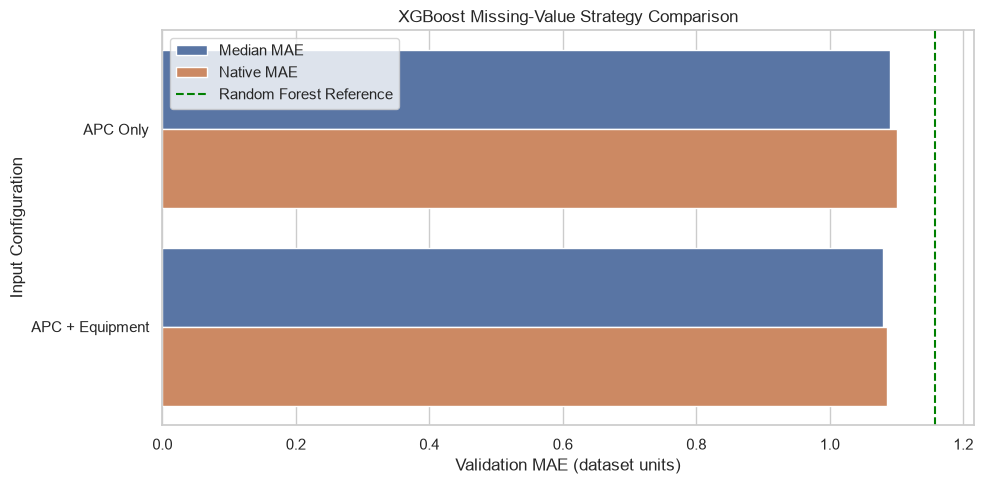

In [10]:

missing_plot_data = missing_comparison.melt(
    id_vars=["Configuration"],
    value_vars=[
        "Median MAE",
        "Native MAE",
    ],
    var_name="Missing Strategy",
    value_name="Validation MAE",
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=missing_plot_data,
    x="Validation MAE",
    y="Configuration",
    hue="Missing Strategy",
)

plt.axvline(
    FOREST_MAE,
    color="green",
    linestyle="--",
    label="Random Forest Reference",
)

plt.title(
    "XGBoost Missing-Value Strategy Comparison"
)

plt.xlabel("Validation MAE (dataset units)")
plt.ylabel("Input Configuration")

plt.legend()
plt.tight_layout()
plt.show()

## 7. XGBoost Model Selection

Rank all XGBoost experiments by validation MAE.

Require finite and positive validation predictions.

Compare RMSE, R2, prediction bias, maximum errors,
and improvement relative to previous benchmarks.

The selected model remains a preliminary candidate.

In [11]:

# STEP 3.4.13 - Compare and select candidates

comparison_columns = [
    "Model",
    "Training MAE",
    "MAE",
    "RMSE",
    "R2",
    "MAPE (%)",
    "Bias",
    "Maximum Absolute Error",
    "P95 Absolute Error",
    "Non-Positive Predictions",
    "Outside Training Target Range",
    "MAE Improvement vs Forest (%)",
]

display(
    all_results_df[comparison_columns]
    .round(6)
)

eligible_results = all_results_df.loc[
    all_results_df[
        "Non-Positive Predictions"
    ] == 0
]

if eligible_results.empty:

    raise ValueError(
        "No physically plausible "
        "XGBoost candidate found."
    )

best_result = (
    eligible_results
    .sort_values("MAE")
    .iloc[0]
)

best_model_name = best_result["Model"]

best_pipeline = trained_xgb_models[
    best_model_name
]

best_predictions = validation_predictions[
    best_model_name
]

best_train_predictions = training_predictions[
    best_model_name
]

best_metrics = evaluate_regression(
    y_val,
    best_predictions,
)

print("Best preliminary XGBoost candidate:")
print(best_model_name)

display(
    best_result.to_frame("Result")
)

,Model,Training MAE,MAE,RMSE,R2,MAPE (%),Bias,Maximum Absolute Error,P95 Absolute Error,Non-Positive Predictions,Outside Training Target Range,MAE Improvement vs Forest (%)
0,"XGB-4 Slow Boosting (APC + Equipment, median)",0.718159,1.079062,1.456193,0.644538,0.710655,-0.029205,6.107028,3.093984,0,0,6.836556
1,"XGB-4 Slow Boosting (APC + Equipment, native)",0.706630,1.085851,1.461776,0.641808,0.714988,-0.047576,6.426761,3.013728,0,0,6.250420
2,"XGB-2 Shallow (APC + Equipment, median)",0.695691,1.086421,1.456615,0.644332,0.715533,-0.015663,6.032026,3.069343,0,0,6.201245
3,"XGB-4 Slow Boosting (APC Only, median)",0.716879,1.090297,1.460278,0.642541,0.718088,-0.041739,5.959079,3.045585,0,0,5.866602
4,"XGB-3 Regularised (APC + Equipment, median)",0.720447,1.090624,1.469362,0.638080,0.718438,-0.016487,6.067981,3.066549,0,0,5.838382
5,"XGB-3 Regularised (APC Only, median)",0.729265,1.099118,1.466369,0.639553,0.724040,-0.027948,6.368116,3.048955,0,0,5.105035
6,"XGB-4 Slow Boosting (APC Only, native)",0.707361,1.100808,1.472487,0.636539,0.724823,-0.055119,6.662906,3.049356,0,0,4.959053
7,"XGB-1 Reference (APC + Equipment, median)",0.127864,1.105670,1.495916,0.624881,0.727855,-0.077765,5.927603,3.064362,0,0,4.539309
8,"XGB-2 Shallow (APC Only, median)",0.704753,1.110232,1.477216,0.634201,0.731468,0.001072,6.131900,3.110519,0,0,4.145455
9,"XGB-1 Reference (APC Only, median)",0.128818,1.116893,1.482235,0.631711,0.735705,-0.064899,6.280048,3.042714,0,0,3.570391


Best preliminary XGBoost candidate:
XGB-4 Slow Boosting (APC + Equipment, median)


,Result
Model,"XGB-4 Slow Boosting (APC + Equipment, median)"
Algorithm,XGBoost
Configuration,APC + Equipment
Boosting Configuration,XGB-4 Slow Boosting
Missing Strategy,median
n_estimators,600
max_depth,4
learning_rate,0.025
min_child_weight,5
reg_alpha,0.1


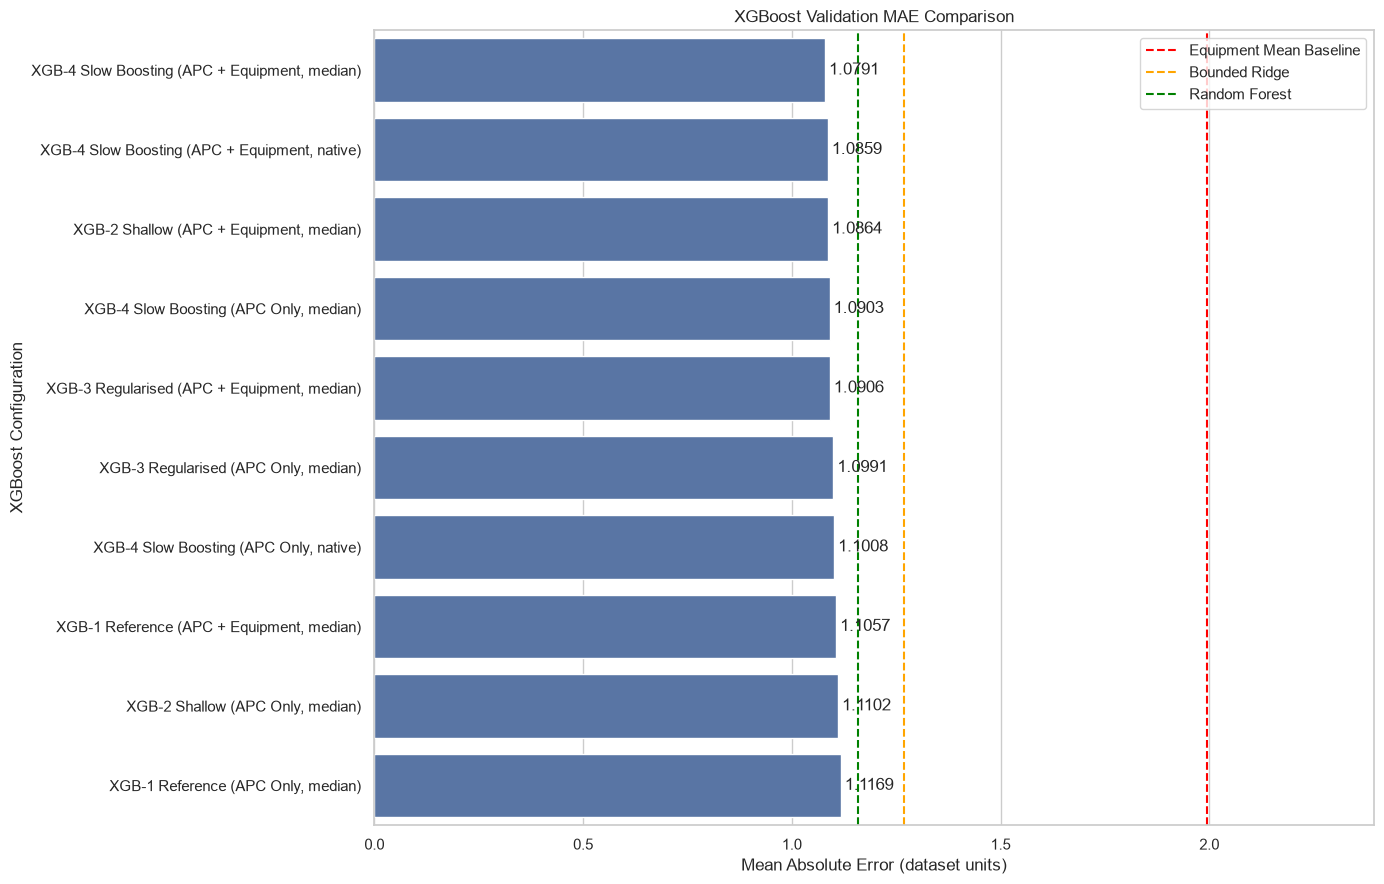

In [12]:

plt.figure(figsize=(14, 9))

ax = sns.barplot(
    data=all_results_df,
    x="MAE",
    y="Model",
)

ax.axvline(
    BASELINE_MAE,
    color="red",
    linestyle="--",
    label="Equipment Mean Baseline",
)

ax.axvline(
    RIDGE_MAE,
    color="orange",
    linestyle="--",
    label="Bounded Ridge",
)

ax.axvline(
    FOREST_MAE,
    color="green",
    linestyle="--",
    label="Random Forest",
)

ax.bar_label(
    ax.containers[0],
    fmt="%.4f",
    padding=3,
)

plt.xlim(
    0,
    max(
        BASELINE_MAE,
        all_results_df["MAE"].max(),
    ) * 1.2,
)

plt.title(
    "XGBoost Validation MAE Comparison"
)

plt.xlabel("Mean Absolute Error (dataset units)")
plt.ylabel("XGBoost Configuration")

plt.legend()
plt.tight_layout()
plt.show()

## 8. Training-Validation Generalisation Analysis

Compare training and validation performance across
XGBoost configurations.

Investigate whether deeper trees and additional
boosting rounds improve future-period predictions.

Generalisation gaps may reflect both overfitting
and temporal distribution shifts.

,Model,Training MAE,Validation MAE,Training R2,Validation R2,Generalisation Gap
0,"XGB-4 Slow Boosting (APC + Equipment, median)",0.718159,1.079062,0.851459,0.644538,0.360903
1,"XGB-4 Slow Boosting (APC + Equipment, native)",0.706630,1.085851,0.855773,0.641808,0.379221
2,"XGB-2 Shallow (APC + Equipment, median)",0.695691,1.086421,0.866600,0.644332,0.390730
3,"XGB-4 Slow Boosting (APC Only, median)",0.716879,1.090297,0.851682,0.642541,0.373418
4,"XGB-3 Regularised (APC + Equipment, median)",0.720447,1.090624,0.850998,0.638080,0.370177
5,"XGB-3 Regularised (APC Only, median)",0.729265,1.099118,0.847383,0.639553,0.369852
6,"XGB-4 Slow Boosting (APC Only, native)",0.707361,1.100808,0.855774,0.636539,0.393448
7,"XGB-1 Reference (APC + Equipment, median)",0.127864,1.105670,0.995387,0.624881,0.977807
8,"XGB-2 Shallow (APC Only, median)",0.704753,1.110232,0.863334,0.634201,0.405479
9,"XGB-1 Reference (APC Only, median)",0.128818,1.116893,0.995239,0.631711,0.988075


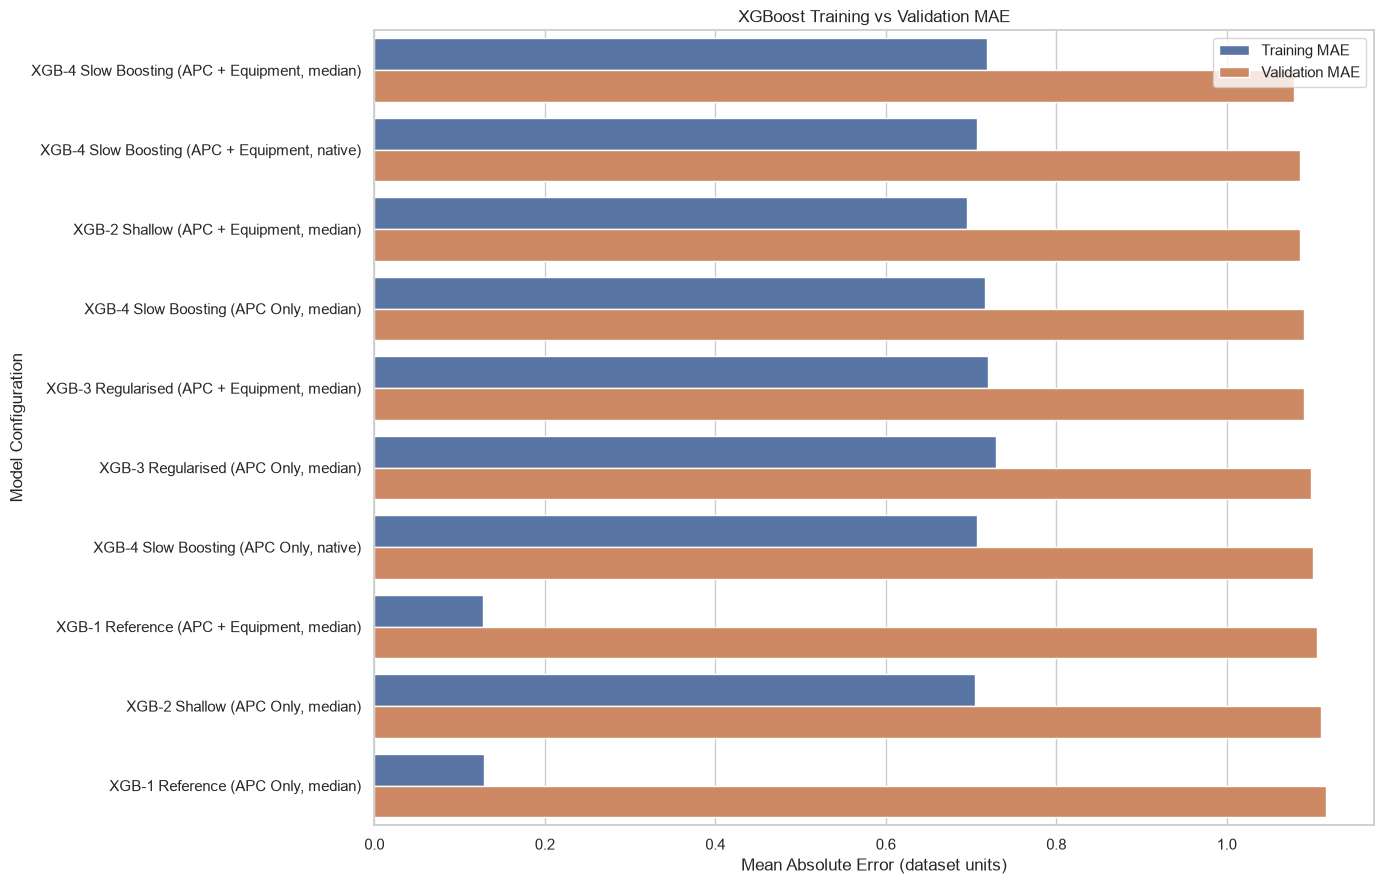

In [13]:

generalisation_summary = all_results_df[
    [
        "Model",
        "Training MAE",
        "MAE",
        "Training R2",
        "R2",
        "Generalisation Gap",
    ]
].rename(
    columns={
        "MAE": "Validation MAE",
        "R2": "Validation R2",
    }
)

display(
    generalisation_summary.round(6)
)

generalisation_plot_data = (
    generalisation_summary.melt(
        id_vars=["Model"],
        value_vars=[
            "Training MAE",
            "Validation MAE",
        ],
        var_name="Partition",
        value_name="MAE",
    )
)

plt.figure(figsize=(14, 9))

sns.barplot(
    data=generalisation_plot_data,
    x="MAE",
    y="Model",
    hue="Partition",
)

plt.title(
    "XGBoost Training vs Validation MAE"
)

plt.xlabel("Mean Absolute Error (dataset units)")
plt.ylabel("Model Configuration")

plt.legend()
plt.tight_layout()
plt.show()

## 9. Equipment Metadata Ablation

Compare matching primary XGBoost configurations
with and without equipment metadata.

Restrict this comparison to median-imputed models
so the missing-value strategy remains unchanged.

Configuration,APC + Equipment,APC Only,Equipment Improvement (%)
Boosting Configuration,,,
XGB-1 Reference,1.105670,1.116893,1.004793
XGB-2 Shallow,1.086421,1.110232,2.144697
XGB-3 Regularised,1.090624,1.099118,0.772799
XGB-4 Slow Boosting,1.079062,1.090297,1.030404


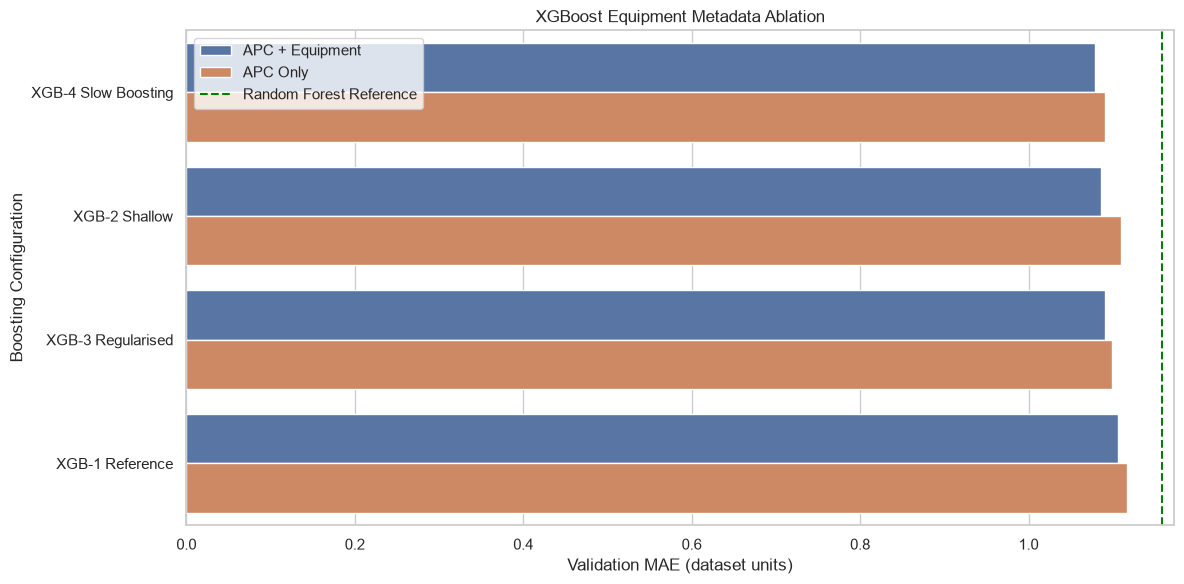

In [14]:

equipment_ablation = (
    primary_results_df.pivot(
        index="Boosting Configuration",
        columns="Configuration",
        values="MAE",
    )
)

equipment_ablation[
    "Equipment Improvement (%)"
] = (
    (
        equipment_ablation["APC Only"]
        - equipment_ablation["APC + Equipment"]
    )
    / equipment_ablation["APC Only"]
    * 100
)

display(
    equipment_ablation.round(6)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=primary_results_df,
    x="MAE",
    y="Boosting Configuration",
    hue="Configuration",
)

plt.axvline(
    FOREST_MAE,
    color="green",
    linestyle="--",
    label="Random Forest Reference",
)

plt.title(
    "XGBoost Equipment Metadata Ablation"
)

plt.xlabel("Validation MAE (dataset units)")
plt.ylabel("Boosting Configuration")

plt.legend()
plt.tight_layout()
plt.show()

## 10. Boosting-Round Performance Analysis

Inspect training and validation MAE at different
boosting-round counts using the fitted candidate.

This is a diagnostic learning curve.

No final test records are evaluated and the
candidate is not automatically modified.

In [15]:

# Retrieve the selected fitted model

best_configuration = best_result["Configuration"]

best_columns = feature_configurations[
    best_configuration
]["columns"]

X_train_best = train_df[best_columns]

X_val_best = val_df[best_columns]

best_preprocessor = (
    best_pipeline.named_steps["preprocessor"]
)

best_regressor = (
    best_pipeline.named_steps["regressor"]
)

X_train_transformed = best_preprocessor.transform(
    X_train_best
)

X_val_transformed = best_preprocessor.transform(
    X_val_best
)

total_rounds = int(
    best_regressor.get_booster()
    .num_boosted_rounds()
)

round_values = sorted(
    set(
        [1, 10, 25, 50]
        + list(range(100, total_rounds + 1, 50))
        + [total_rounds]
    )
)

round_values = [
    value
    for value in round_values
    if value <= total_rounds
]

learning_curve_results = []

for rounds in round_values:

    train_pred = best_regressor.predict(
        X_train_transformed,
        iteration_range=(0, rounds),
    )

    val_pred = best_regressor.predict(
        X_val_transformed,
        iteration_range=(0, rounds),
    )

    train_mae = evaluate_regression(
        y_train,
        train_pred,
    )["MAE"]

    val_mae = evaluate_regression(
        y_val,
        val_pred,
    )["MAE"]

    learning_curve_results.append({
        "Boosting Rounds": rounds,
        "Training MAE": train_mae,
        "Validation MAE": val_mae,
    })

learning_curve_df = pd.DataFrame(
    learning_curve_results
)

display(
    learning_curve_df.round(6)
)

assert np.isclose(
    learning_curve_df.iloc[-1]["Validation MAE"],
    best_metrics["MAE"],
)

best_observed_round = (
    learning_curve_df
    .sort_values("Validation MAE")
    .iloc[0]
)

print(
    "Lowest-MAE inspected boosting round:",
    int(best_observed_round["Boosting Rounds"])
)

print(
    "Observed validation MAE:",
    best_observed_round["Validation MAE"]
)

,Boosting Rounds,Training MAE,Validation MAE
0,1,1.911259,2.037408
1,10,1.793772,1.884306
2,25,1.646926,1.699242
3,50,1.481274,1.527484
4,100,1.278715,1.344615
5,150,1.160930,1.252843
6,200,1.064721,1.196503
7,250,0.988993,1.157779
8,300,0.933659,1.135517
9,350,0.887853,1.120526


Lowest-MAE inspected boosting round: 600
Observed validation MAE: 1.0790623717414562


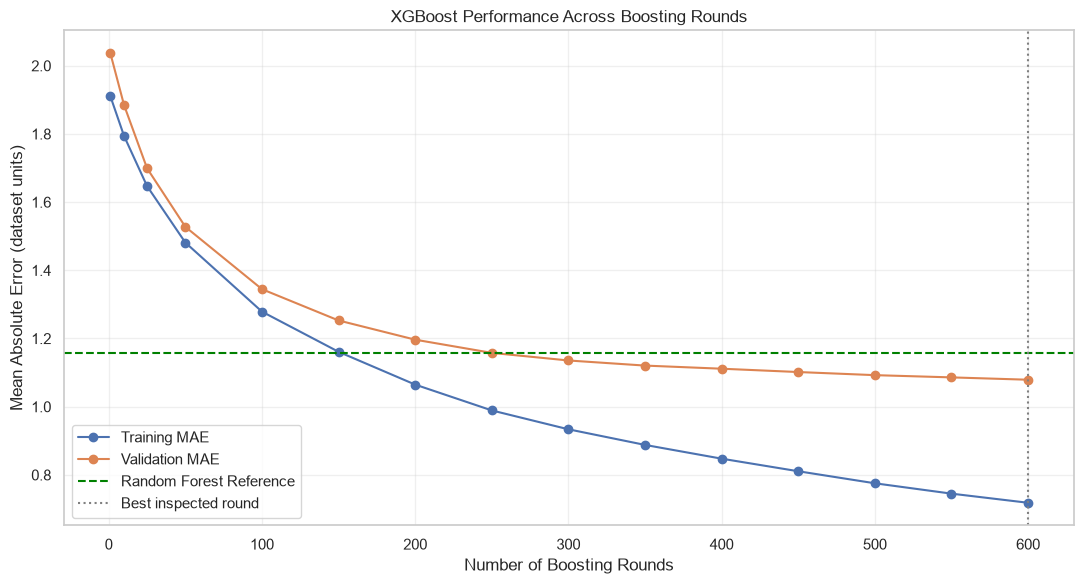

In [16]:

plt.figure(figsize=(11, 6))

plt.plot(
    learning_curve_df["Boosting Rounds"],
    learning_curve_df["Training MAE"],
    marker="o",
    label="Training MAE",
)

plt.plot(
    learning_curve_df["Boosting Rounds"],
    learning_curve_df["Validation MAE"],
    marker="o",
    label="Validation MAE",
)

plt.axhline(
    FOREST_MAE,
    color="green",
    linestyle="--",
    label="Random Forest Reference",
)

plt.axvline(
    best_observed_round["Boosting Rounds"],
    color="grey",
    linestyle=":",
    label="Best inspected round",
)

plt.title(
    "XGBoost Performance Across Boosting Rounds"
)

plt.xlabel("Number of Boosting Rounds")
plt.ylabel("Mean Absolute Error (dataset units)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Cross-Model Benchmark Comparison

Compare the best preliminary XGBoost candidate
against the equipment mean baseline, bounded Ridge,
and Random Forest.

All reference metrics are obtained from the
same chronological validation partition.

,Model,MAE,RMSE,R2,MAPE (%),Bias
0,XGBoost,1.079062,1.456193,0.644538,0.710655,-0.029205
1,Random Forest,1.158247,1.529514,0.607841,0.763190,0.028238
2,Bounded Ridge,1.267788,1.673137,0.530735,0.834860,-0.121325
3,Equipment Mean,1.995479,2.444380,-0.001596,1.320842,0.664447


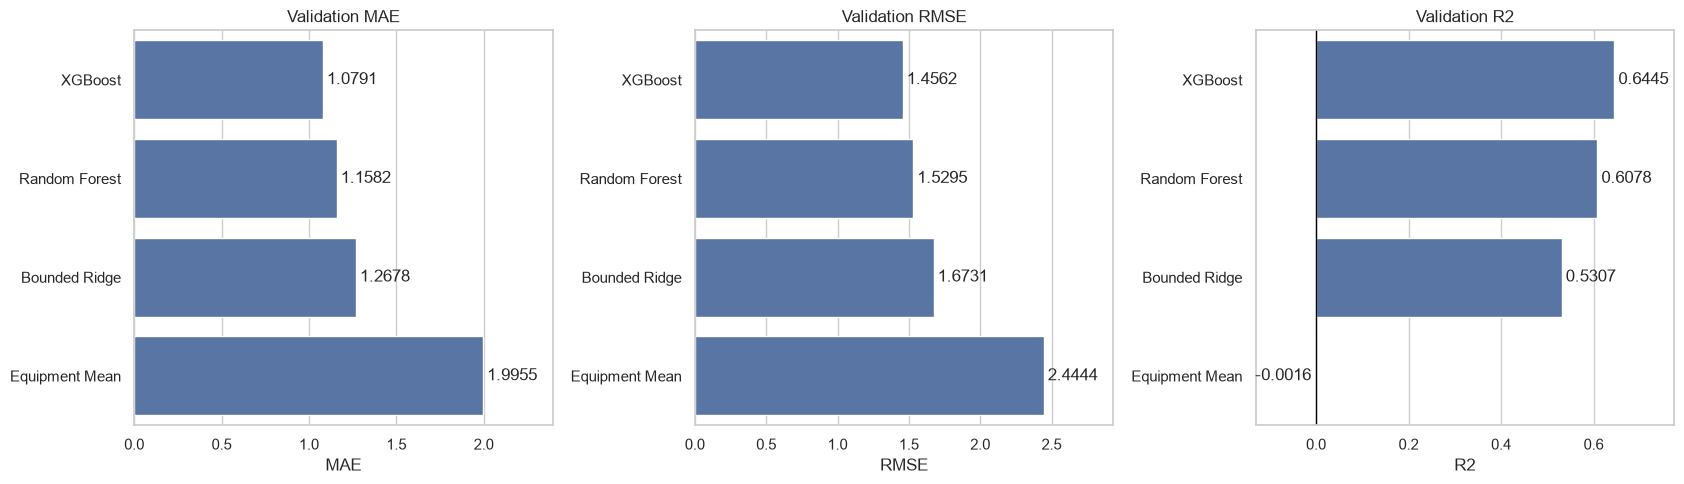

In [17]:

baseline_row = next(
    result
    for result in baseline_experiment["results"]
    if result["Model"]
    == baseline_experiment["best_baseline"]
)

ridge_row = next(
    result
    for result in ridge_experiment["results"]
    if result["Model"]
    == ridge_experiment["best_model"]
)

forest_row = next(
    result
    for result in forest_experiment["results"]
    if result["Model"]
    == forest_experiment["best_model"]
)

metric_columns = [
    "MAE",
    "RMSE",
    "R2",
    "MAPE (%)",
    "Bias",
]

benchmark_rows = []

for model_name, metrics in [
    ("Equipment Mean", baseline_row),
    ("Bounded Ridge", ridge_row),
    ("Random Forest", forest_row),
    ("XGBoost", best_metrics),
]:

    benchmark_rows.append({
        "Model": model_name,
        **{
            metric: metrics[metric]
            for metric in metric_columns
        },
    })

benchmark_comparison = (
    pd.DataFrame(benchmark_rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    benchmark_comparison.round(6)
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
)

for ax, metric in zip(
    axes,
    ["MAE", "RMSE", "R2"],
):

    sns.barplot(
        data=benchmark_comparison,
        x=metric,
        y="Model",
        ax=ax,
    )

    ax.bar_label(
        ax.containers[0],
        fmt="%.4f",
        padding=3,
    )

    ax.set_title(f"Validation {metric}")

    ax.set_ylabel("")

    if metric == "R2":

        ax.axvline(
            0,
            color="black",
            linewidth=1,
        )

    ax.margins(x=0.2)

plt.tight_layout()
plt.show()

## 12. Prediction and Residual Analysis

Examine actual versus predicted thickness,
signed residuals, and absolute-error distributions.

Investigate systematic prediction bias and
prediction behaviour at extreme thickness values.

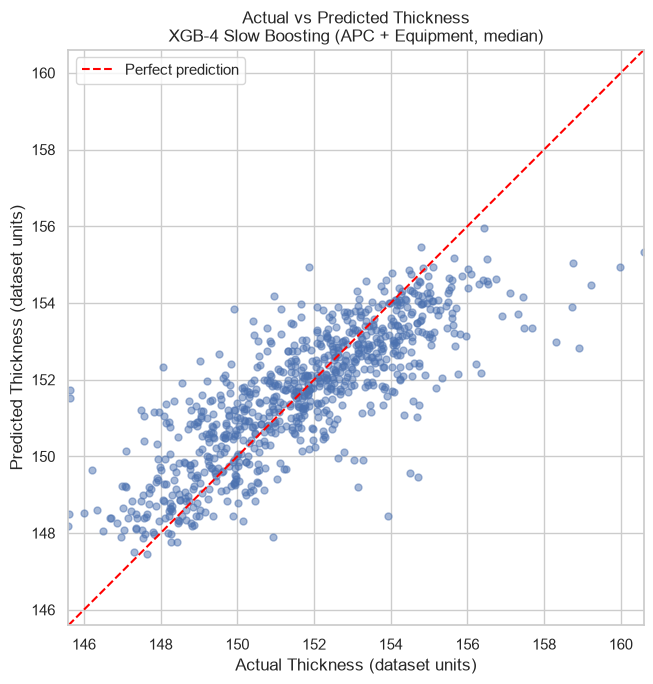

In [18]:

lower = min(
    y_val.min(),
    best_predictions.min(),
)

upper = max(
    y_val.max(),
    best_predictions.max(),
)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    best_predictions,
    alpha=0.5,
    s=25,
)

plt.plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="Perfect prediction",
)

plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.gca().set_aspect(
    "equal",
    adjustable="box",
)

plt.title(
    f"Actual vs Predicted Thickness\n"
    f"{best_model_name}"
)

plt.xlabel("Actual Thickness (dataset units)")
plt.ylabel("Predicted Thickness (dataset units)")

plt.legend()
plt.tight_layout()
plt.show()

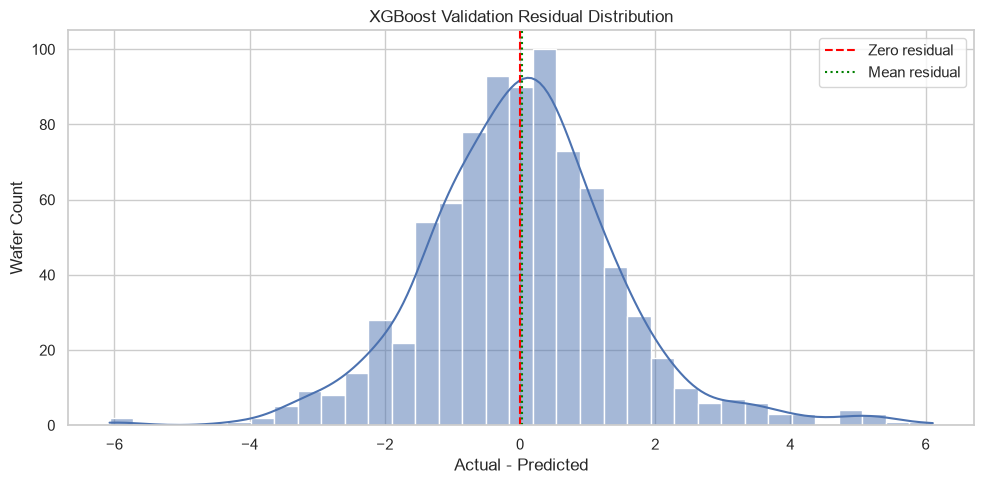

In [19]:

residuals = (
    y_val.to_numpy() - best_predictions
)

plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=35,
    kde=True,
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero residual",
)

plt.axvline(
    residuals.mean(),
    color="green",
    linestyle=":",
    label="Mean residual",
)

plt.title(
    "XGBoost Validation Residual Distribution"
)

plt.xlabel("Actual - Predicted")
plt.ylabel("Wafer Count")

plt.legend()
plt.tight_layout()
plt.show()

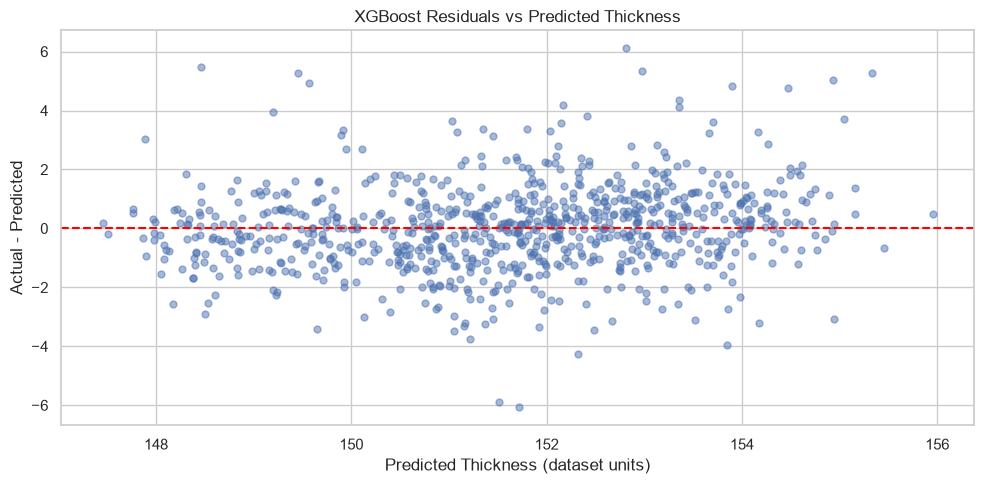

In [20]:

plt.figure(figsize=(10, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.5,
    s=25,
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
)

plt.title(
    "XGBoost Residuals vs Predicted Thickness"
)

plt.xlabel("Predicted Thickness (dataset units)")
plt.ylabel("Actual - Predicted")

plt.tight_layout()
plt.show()

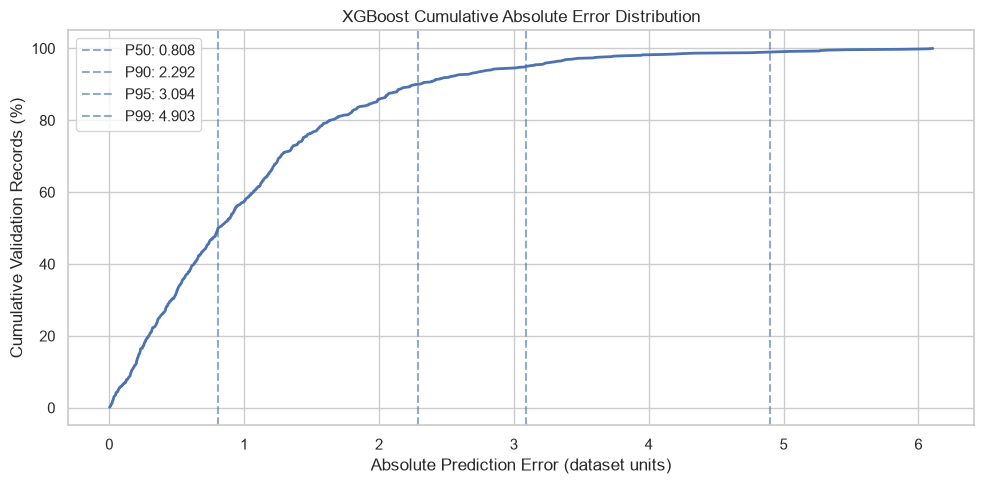

P50     0.807756
P90     2.291843
P95     3.093984
P99     4.902625
P100    6.107028
Name: Absolute Error, dtype: float64

In [21]:

absolute_errors = np.abs(residuals)

sorted_errors = np.sort(absolute_errors)

cumulative_percentage = (
    np.arange(1, len(sorted_errors) + 1)
    / len(sorted_errors)
    * 100
)

plt.figure(figsize=(10, 5))

plt.plot(
    sorted_errors,
    cumulative_percentage,
    linewidth=2,
)

for percentile in [50, 90, 95, 99]:

    error_value = np.percentile(
        absolute_errors,
        percentile,
    )

    plt.axvline(
        error_value,
        linestyle="--",
        alpha=0.6,
        label=(
            f"P{percentile}: "
            f"{error_value:.3f}"
        ),
    )

plt.title(
    "XGBoost Cumulative Absolute Error Distribution"
)

plt.xlabel("Absolute Prediction Error (dataset units)")
plt.ylabel("Cumulative Validation Records (%)")

plt.legend()
plt.tight_layout()
plt.show()

error_percentiles = {
    f"P{p}": float(
        np.percentile(absolute_errors, p)
    )
    for p in [50, 90, 95, 99, 100]
}

display(
    pd.Series(
        error_percentiles,
        name="Absolute Error",
    ).round(6)
)

## 13. Prediction Robustness Investigation

Verify finite predictions and report non-positive
thickness predictions for every XGBoost model.

Report predictions outside the training target range.

Revisit the two historical catastrophic linear
extrapolation cases.

Prediction range diagnostics are not substitutes
for engineering acceptance specifications.

In [22]:

robustness_summary = []

training_target_min = float(y_train.min())

training_target_max = float(y_train.max())

for model_name, predictions in (
    validation_predictions.items()
):

    assert len(predictions) == len(y_val)
    assert np.isfinite(predictions).all()

    outside_range = (
        (predictions < training_target_min)
        |
        (predictions > training_target_max)
    )

    robustness_summary.append({
        "Model": model_name,

        "Minimum Prediction": float(
            predictions.min()
        ),

        "Maximum Prediction": float(
            predictions.max()
        ),

        "Non-Positive Predictions": int(
            (predictions <= 0).sum()
        ),

        "Outside Training Target Range": int(
            outside_range.sum()
        ),
    })

robustness_summary_df = pd.DataFrame(
    robustness_summary
)

display(
    robustness_summary_df.round(6)
)

print("Training target minimum:", training_target_min)
print("Training target maximum:", training_target_max)

print(
    "\nSelected candidate non-positive predictions:",
    int((best_predictions <= 0).sum())
)

assert (best_predictions > 0).all()


,Model,Minimum Prediction,Maximum Prediction,Non-Positive Predictions,Outside Training Target Range
0,"XGB-1 Reference (APC Only, median)",147.046906,156.313858,0,0
1,"XGB-2 Shallow (APC Only, median)",147.039337,155.970474,0,0
2,"XGB-3 Regularised (APC Only, median)",147.516571,156.028702,0,0
3,"XGB-4 Slow Boosting (APC Only, median)",147.353546,155.921204,0,0
4,"XGB-1 Reference (APC + Equipment, median)",147.254532,155.691254,0,0
5,"XGB-2 Shallow (APC + Equipment, median)",146.910110,156.284317,0,0
6,"XGB-3 Regularised (APC + Equipment, median)",147.456146,155.996704,0,0
7,"XGB-4 Slow Boosting (APC + Equipment, median)",147.455841,155.951767,0,0
8,"XGB-4 Slow Boosting (APC Only, native)",147.572693,156.028259,0,0
9,"XGB-4 Slow Boosting (APC + Equipment, native)",147.391785,155.882828,0,0


Training target minimum: 141.9620738610548
Training target maximum: 163.64180029940047

Selected candidate non-positive predictions: 0


In [23]:

previous_problem_wafer_ids = [
    "V6G022UK04",
    "V6G01XL921",
]

failure_case_df = val_df[
    [
        "wafer_id",
        "equipment",
        "runstart",
        TARGET,
    ]
].copy()

failure_case_df["XGBoost Prediction"] = (
    best_predictions
)

failure_case_df["Absolute Error"] = (
    failure_case_df[TARGET]
    - failure_case_df["XGBoost Prediction"]
).abs()

previous_failure_cases = failure_case_df.loc[
    failure_case_df["wafer_id"].isin(
        previous_problem_wafer_ids
    )
].copy()

assert len(previous_failure_cases) == 2

display(
    previous_failure_cases.round({
        TARGET: 6,
        "XGBoost Prediction": 6,
        "Absolute Error": 6,
    })
)

,wafer_id,equipment,runstart,mean_thickness,XGBoost Prediction,Absolute Error
717,V6G022UK04,equipment_1,2024-06-23 16:38:19,149.381522,149.957291,0.575769
720,V6G01XL921,equipment_14,2024-06-24 11:24:52,148.487949,149.020859,0.532910


## 14. Input Distribution Warning Analysis

Apply the established training-standardised sensor
warning heuristic to the XGBoost validation records.

Compare prediction errors between flagged and
unflagged observations.

This heuristic is not a calibrated prediction
uncertainty estimator.

In [24]:

from ml.preprocessing import build_preprocessor

diagnostic_preprocessor = build_preprocessor(
    numeric_features=apc_features,
    include_equipment=False,
    scale_numeric=True,
    clip_z=None,
)

diagnostic_preprocessor.fit(
    train_df[apc_features]
)

diagnostic_z = diagnostic_preprocessor.transform(
    val_df[apc_features]
)

sensor_z = diagnostic_z[
    :,
    :len(apc_features)
]

WARNING_BOUND = 5.0

sensor_warning_flags = (
    np.abs(sensor_z) > WARNING_BOUND
)

warning_error_df = pd.DataFrame({
    "equipment": val_df["equipment"].to_numpy(),

    "Actual": y_val.to_numpy(),

    "Predicted": best_predictions,

    "Flagged Sensors": (
        sensor_warning_flags.sum(axis=1)
    ),

    "Maximum Absolute Sensor Z": (
        np.abs(sensor_z).max(axis=1)
    ),
})

warning_error_df["Sensor Warning"] = (
    warning_error_df["Flagged Sensors"] > 0
)

warning_error_df["Absolute Error"] = (
    warning_error_df["Actual"]
    - warning_error_df["Predicted"]
).abs()

warning_error_df["Squared Error"] = (
    warning_error_df["Absolute Error"] ** 2
)

warning_summary = (
    warning_error_df
    .groupby("Sensor Warning")
    .agg(
        Records=("Actual", "count"),
        MAE=("Absolute Error", "mean"),
        MSE=("Squared Error", "mean"),
        Maximum_Error=("Absolute Error", "max"),
    )
)

warning_summary["RMSE"] = np.sqrt(
    warning_summary.pop("MSE")
)

display(
    warning_summary.round(6)
)

print(
    "Flagged validation records:",
    int(
        warning_error_df["Sensor Warning"].sum()
    )
)

,Records,MAE,Maximum_Error,RMSE
Sensor Warning,,,,
False,173,1.118196,6.071332,1.493489
True,661,1.068820,6.107028,1.446273


Flagged validation records: 661


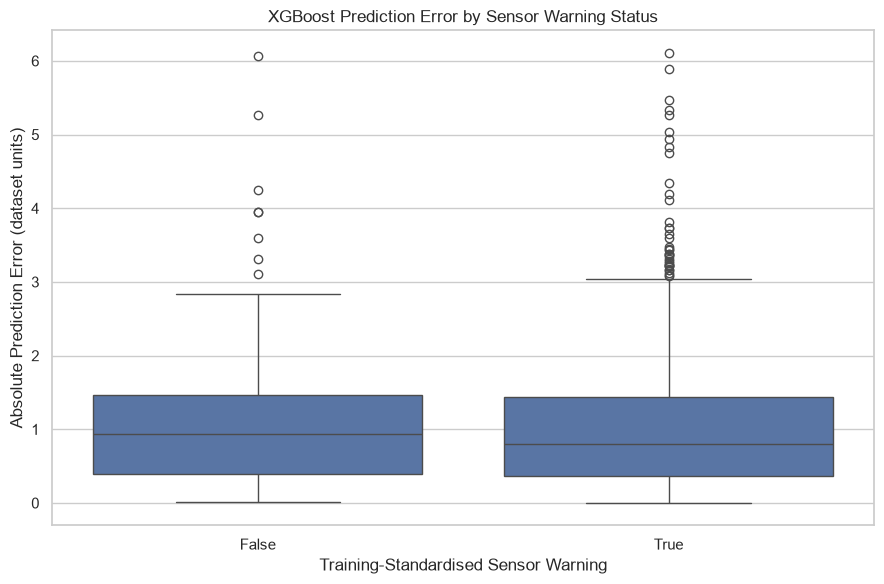

In [25]:

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=warning_error_df,
    x="Sensor Warning",
    y="Absolute Error",
    order=[False, True],
)

plt.title(
    "XGBoost Prediction Error by Sensor Warning Status"
)

plt.xlabel("Training-Standardised Sensor Warning")
plt.ylabel("Absolute Prediction Error (dataset units)")

plt.tight_layout()
plt.show()


## 15. XGBoost Feature Importance

Extract normalised gain-based importance scores
for transformed model inputs.

Compare process measurement importance with
equipment metadata and missingness indicators.

Gain-based importance describes the fitted model
and does not establish physical causality.

In [26]:

importance_df = (
    extract_xgboost_feature_importance(
        best_pipeline
    )
)

print(
    "Transformed feature count:",
    len(importance_df)
)

print(
    "Total normalised importance:",
    importance_df["Importance"].sum()
)

display(
    importance_df.head(20).round(6)
)

Transformed feature count: 173
Total normalised importance: 1.0


,Feature,Importance
0,numeric__LIFE_TARGET_RUN_A,0.073672
1,numeric__AMPS_TARGET_20_90_DEP1_SPS_X,0.047154
2,numeric__LIFE_TARGET_DEP1_A,0.045957
3,numeric__AMPS_TARGET_20_90_DEP1_SPS_M,0.038355
4,numeric__missingindicator_AMPS_TARGET_RECIPE_A,0.033115
5,equipment__equipment_equipment_12,0.031308
6,numeric__missingindicator_VOLTS_TARGET_DEP1_R,0.029934
7,numeric__AMPS_TARGET_20_95_DEP1_X,0.026416
8,numeric__missingindicator_T_RECIPE_ENG,0.023714
9,numeric__UTILISATION_TARGET_RUN_A,0.020851


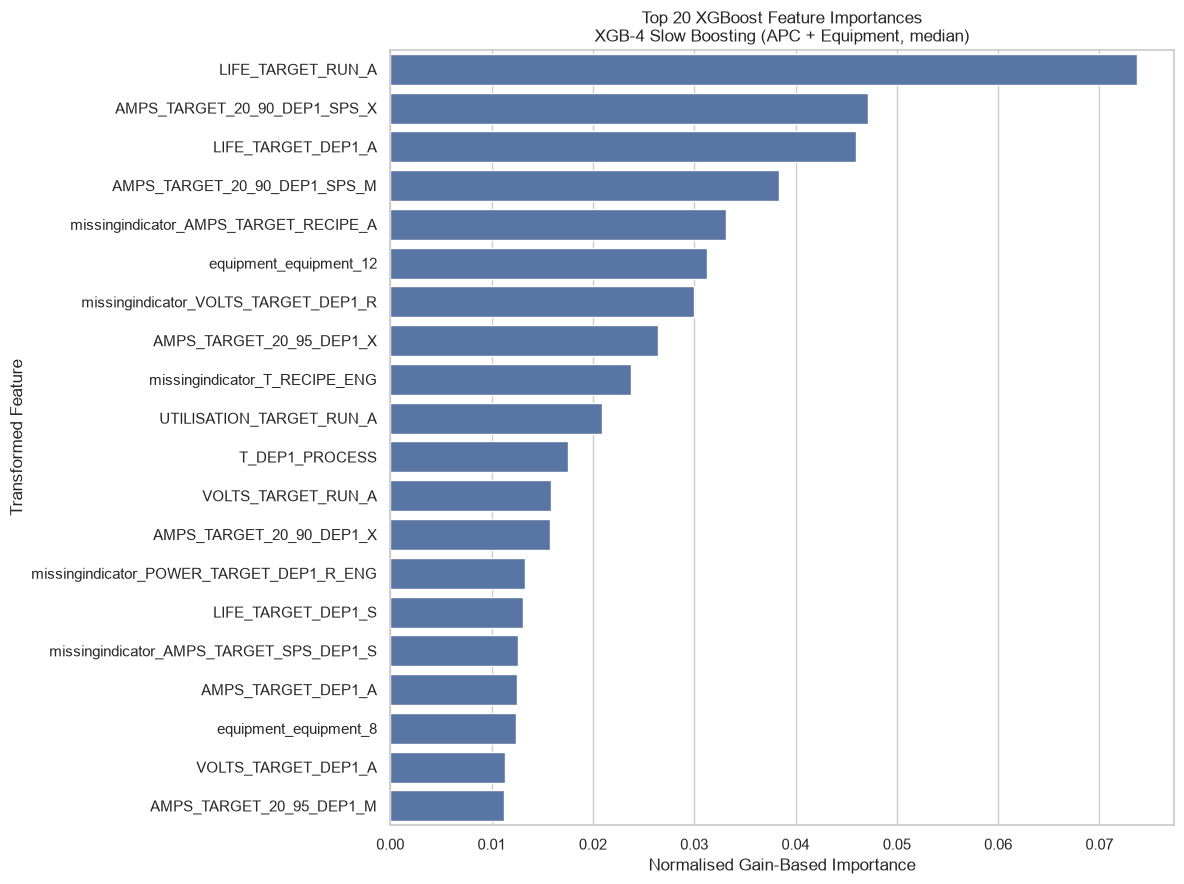

In [27]:

top_importance = importance_df.head(20).copy()

top_importance["Feature"] = (
    top_importance["Feature"]
    .str.replace(
        "numeric__",
        "",
        regex=False,
    )
    .str.replace(
        "equipment__",
        "",
        regex=False,
    )
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=top_importance,
    x="Importance",
    y="Feature",
)

plt.title(
    f"Top 20 XGBoost Feature Importances\n"
    f"{best_model_name}"
)

plt.xlabel("Normalised Gain-Based Importance")
plt.ylabel("Transformed Feature")

plt.tight_layout()
plt.show()

,Importance,Importance (%)
Feature Group,,
APC Measurements,0.714887,71.488747
Equipment Metadata,0.101532,10.153230
Missingness Indicators,0.183580,18.358030


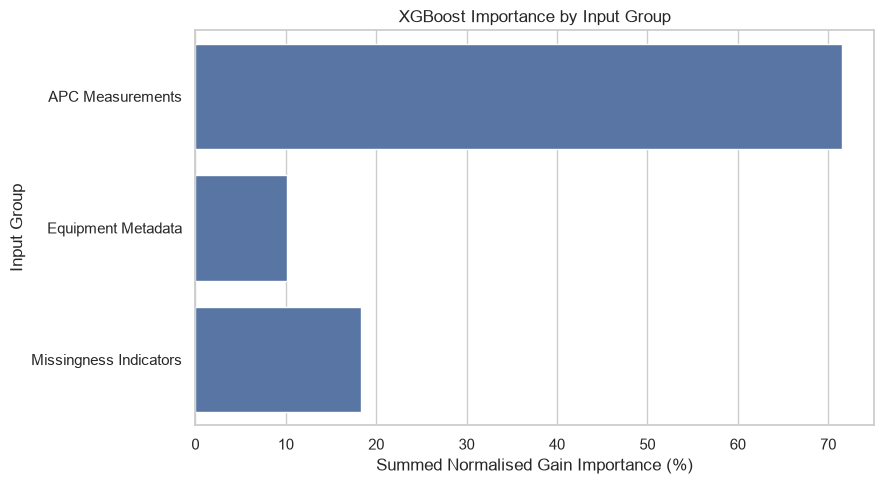

In [28]:

importance_groups = importance_df.copy()


def classify_transformed_feature(name):

    if name.startswith("equipment__"):

        return "Equipment Metadata"

    if name.startswith(
        "numeric__missingindicator_"
    ):

        return "Missingness Indicators"

    return "APC Measurements"


importance_groups["Feature Group"] = (
    importance_groups["Feature"]
    .apply(classify_transformed_feature)
)

grouped_importance = (
    importance_groups
    .groupby("Feature Group")["Importance"]
    .sum()
    .to_frame()
)

grouped_importance["Importance (%)"] = (
    grouped_importance["Importance"] * 100
)

display(
    grouped_importance.round(6)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=grouped_importance.reset_index(),
    x="Importance (%)",
    y="Feature Group",
)

plt.title(
    "XGBoost Importance by Input Group"
)

plt.xlabel("Summed Normalised Gain Importance (%)")
plt.ylabel("Input Group")

plt.tight_layout()
plt.show()

## 16. Equipment-Level Validation Performance

Evaluate sample counts, MAE, RMSE, signed bias,
and maximum absolute errors across equipment groups.

Investigate whether XGBoost reduces the systematic
equipment-specific errors observed in Random Forest.

These observations do not establish equipment faults.

In [29]:

equipment_errors = pd.DataFrame({
    "equipment": val_df["equipment"].to_numpy(),
    "Actual": y_val.to_numpy(),
    "Predicted": best_predictions,
})

equipment_errors["Absolute Error"] = (
    equipment_errors["Actual"]
    - equipment_errors["Predicted"]
).abs()

equipment_errors["Squared Error"] = (
    equipment_errors["Absolute Error"] ** 2
)

equipment_errors["Bias"] = (
    equipment_errors["Predicted"]
    - equipment_errors["Actual"]
)

equipment_error_summary = (
    equipment_errors
    .groupby("equipment")
    .agg(
        Records=("Actual", "count"),
        MAE=("Absolute Error", "mean"),
        MSE=("Squared Error", "mean"),
        Bias=("Bias", "mean"),
        Maximum_Error=("Absolute Error", "max"),
    )
)

equipment_error_summary["RMSE"] = np.sqrt(
    equipment_error_summary.pop("MSE")
)

equipment_error_summary = (
    equipment_error_summary[
        [
            "Records",
            "MAE",
            "RMSE",
            "Bias",
            "Maximum_Error",
        ]
    ]
    .sort_values(
        "MAE",
        ascending=False,
    )
)

display(
    equipment_error_summary.round(6)
)

,Records,MAE,RMSE,Bias,Maximum_Error
equipment,,,,,
equipment_16,47,1.787566,2.003538,1.787566,3.737010
equipment_11,50,1.525882,2.099418,0.273021,6.071332
equipment_1,56,1.435294,1.646278,-1.232205,3.652230
equipment_13,54,1.388847,1.630249,1.241524,3.220063
equipment_14,56,1.363086,1.675091,-1.050524,4.835488
equipment_3,47,1.308155,1.953545,-0.709881,6.107028
equipment_7,48,1.107444,1.459939,-0.203537,4.112595
equipment_8,54,1.096020,1.357547,0.234211,3.155752
equipment_15,50,0.991878,1.310933,-0.041577,4.341562


In [30]:

forest_equipment_summary = pd.DataFrame(
    forest_experiment["equipment_error_summary"]
)

equipment_comparison = (
    equipment_error_summary
    .reset_index()
    .merge(
        forest_equipment_summary,
        on="equipment",
        suffixes=("_XGB", "_RF"),
        validate="one_to_one",
    )
)

assert (
    equipment_comparison["Records_XGB"]
    == equipment_comparison["Records_RF"]
).all()

equipment_comparison[
    "MAE Improvement vs Forest (%)"
] = (
    (
        equipment_comparison["MAE_RF"]
        - equipment_comparison["MAE_XGB"]
    )
    / equipment_comparison["MAE_RF"]
    * 100
)

display(
    equipment_comparison[
        [
            "equipment",
            "Records_XGB",
            "MAE_RF",
            "MAE_XGB",
            "Bias_RF",
            "Bias_XGB",
            "MAE Improvement vs Forest (%)",
        ]
    ].round(6)
)

,equipment,Records_XGB,MAE_RF,MAE_XGB,Bias_RF,Bias_XGB,MAE Improvement vs Forest (%)
0,equipment_16,47,1.812130,1.787566,1.812130,1.787566,1.355562
1,equipment_11,50,1.655560,1.525882,0.320229,0.273021,7.832881
2,equipment_1,56,1.339391,1.435294,-1.154988,-1.232205,-7.160236
3,equipment_13,54,1.400074,1.388847,1.248827,1.241524,0.801877
4,equipment_14,56,1.399586,1.363086,-1.043172,-1.050524,2.607949
5,equipment_3,47,1.576697,1.308155,-0.919465,-0.709881,17.031965
6,equipment_7,48,1.120338,1.107444,-0.172871,-0.203537,1.150963
7,equipment_8,54,1.427861,1.096020,0.459633,0.234211,23.240452
8,equipment_15,50,1.336972,0.991878,0.532495,-0.041577,25.811646
9,equipment_6,57,0.847930,0.912522,0.273039,0.541160,-7.617608


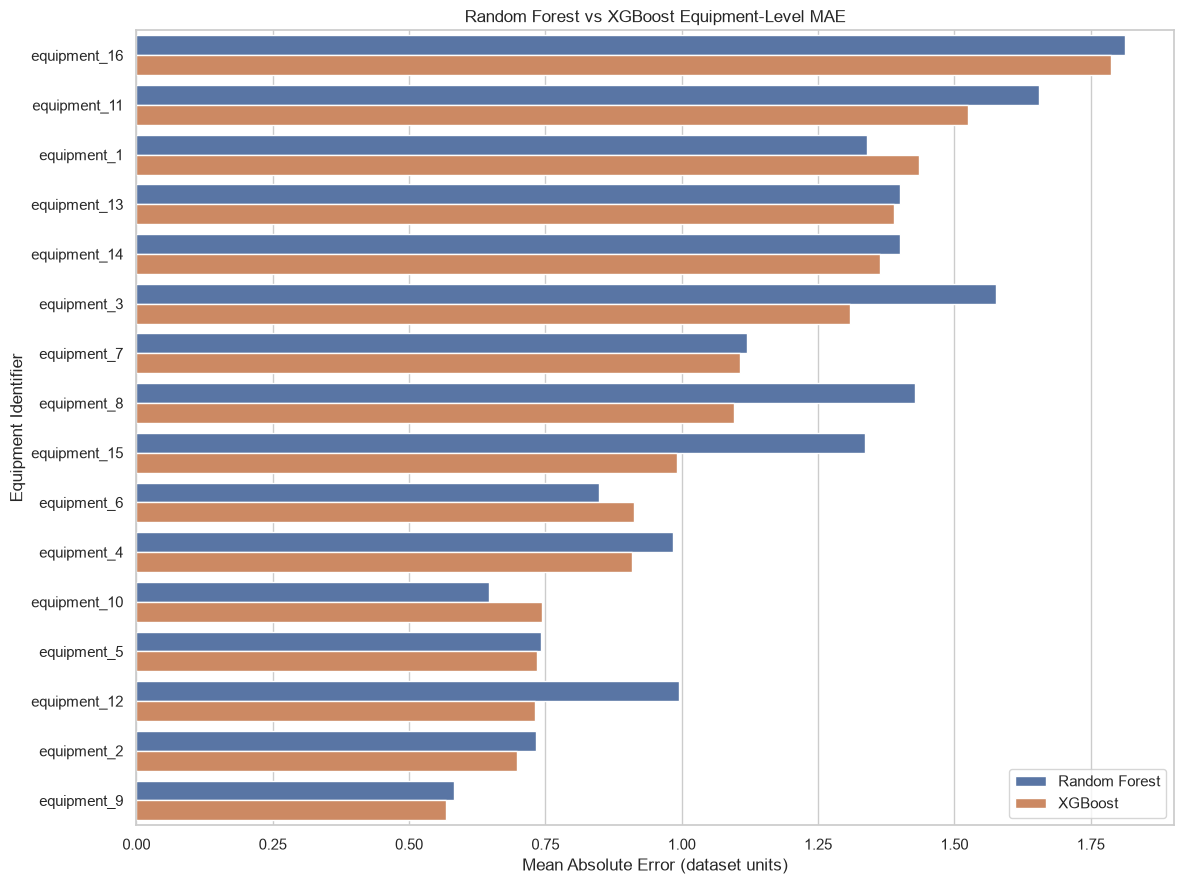

In [31]:

equipment_plot_data = equipment_comparison.melt(
    id_vars=["equipment"],
    value_vars=[
        "MAE_RF",
        "MAE_XGB",
    ],
    var_name="Model",
    value_name="MAE",
)

equipment_plot_data["Model"] = (
    equipment_plot_data["Model"]
    .map({
        "MAE_RF": "Random Forest",
        "MAE_XGB": "XGBoost",
    })
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=equipment_plot_data,
    x="MAE",
    y="equipment",
    hue="Model",
)

plt.title(
    "Random Forest vs XGBoost Equipment-Level MAE"
)

plt.xlabel("Mean Absolute Error (dataset units)")
plt.ylabel("Equipment Identifier")

plt.legend()
plt.tight_layout()
plt.show()

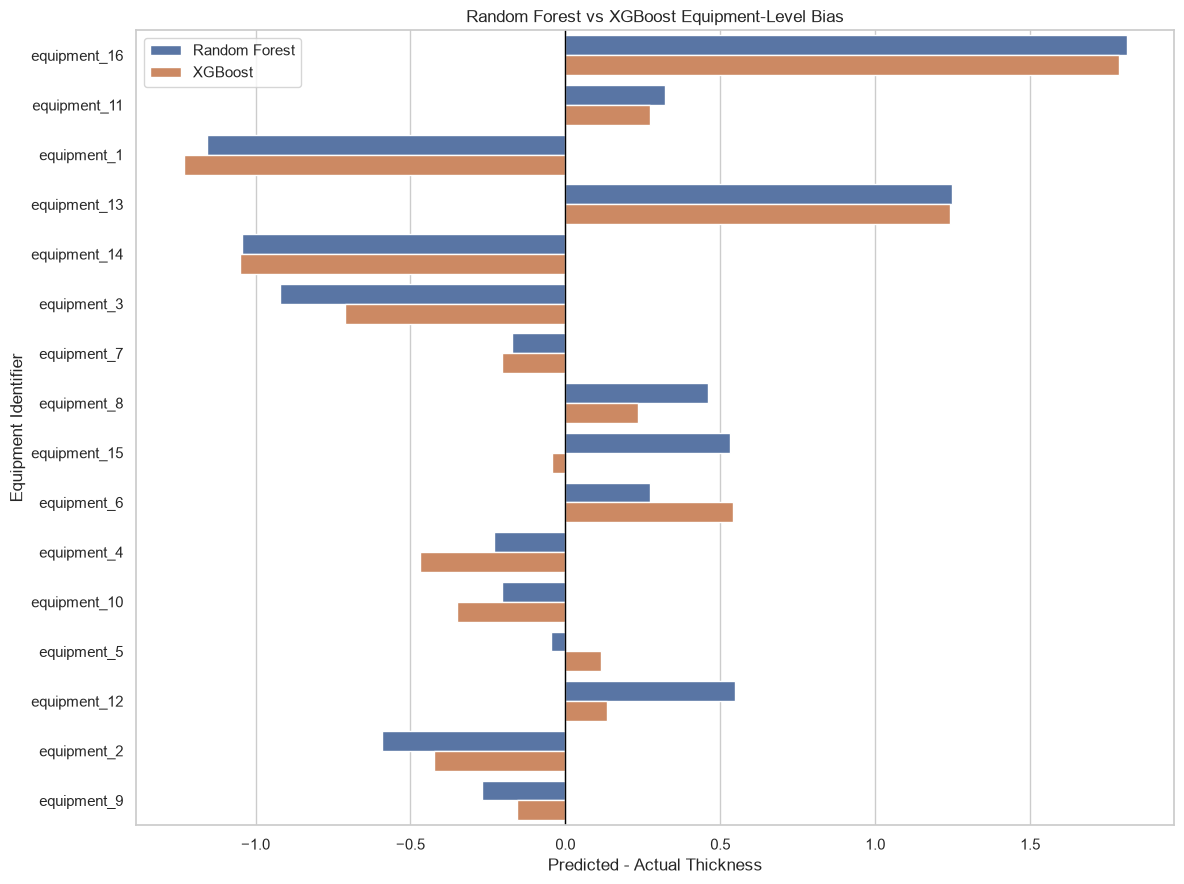

In [32]:

bias_plot_data = equipment_comparison.melt(
    id_vars=["equipment"],
    value_vars=[
        "Bias_RF",
        "Bias_XGB",
    ],
    var_name="Model",
    value_name="Bias",
)

bias_plot_data["Model"] = (
    bias_plot_data["Model"]
    .map({
        "Bias_RF": "Random Forest",
        "Bias_XGB": "XGBoost",
    })
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=bias_plot_data,
    x="Bias",
    y="equipment",
    hue="Model",
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    "Random Forest vs XGBoost Equipment-Level Bias"
)

plt.xlabel("Predicted - Actual Thickness")
plt.ylabel("Equipment Identifier")

plt.legend()
plt.tight_layout()
plt.show()

## 17. Model Complexity and Computational Cost

Measure fitted boosting rounds, tree nodes, leaf
counts, training time and serialized pipeline size.

Investigate accuracy-complexity trade-offs for
potential backend deployment.

Serialized size is an approximate deployment
indicator, not a measurement of runtime memory.

In [33]:

import pickle

complexity_results = []

for model_name, pipeline in (
    trained_xgb_models.items()
):

    regressor = pipeline.named_steps[
        "regressor"
    ]

    booster = regressor.get_booster()

    tree_df = booster.trees_to_dataframe()

    total_trees = int(
        tree_df["Tree"].nunique()
    )

    total_nodes = len(tree_df)

    total_leaves = int(
        (tree_df["Feature"] == "Leaf").sum()
    )

    pipeline_size_bytes = len(
        pickle.dumps(
            pipeline,
            protocol=pickle.HIGHEST_PROTOCOL,
        )
    )

    complexity_results.append({
        "Model": model_name,

        "Boosting Rounds": int(
            booster.num_boosted_rounds()
        ),

        "Trees": total_trees,

        "Total Tree Nodes": total_nodes,

        "Total Tree Leaves": total_leaves,

        "Mean Leaves per Tree": (
            total_leaves / total_trees
        ),

        "Serialized Size (MiB)": (
            pipeline_size_bytes / 1024**2
        ),
    })

complexity_df = pd.DataFrame(
    complexity_results
)

complexity_summary = all_results_df[
    [
        "Model",
        "MAE",
        "Training Time (s)",
        "Validation Prediction Time (s)",
    ]
].merge(
    complexity_df,
    on="Model",
    validate="one_to_one",
)

display(
    complexity_summary.round(6)
)

,Model,MAE,Training Time (s),Validation Prediction Time (s),Boosting Rounds,Trees,Total Tree Nodes,Total Tree Leaves,Mean Leaves per Tree,Serialized Size (MiB)
0,"XGB-4 Slow Boosting (APC + Equipment, median)",1.079062,2.284096,0.014653,600,600,16282,8441,14.068333,0.921866
1,"XGB-4 Slow Boosting (APC + Equipment, native)",1.085851,1.890239,0.012247,600,600,16196,8398,13.996667,0.917688
2,"XGB-2 Shallow (APC + Equipment, median)",1.086421,1.042827,0.015104,300,300,4408,2354,7.846667,0.347725
3,"XGB-4 Slow Boosting (APC Only, median)",1.090297,2.075858,0.011617,600,600,16322,8461,14.101667,0.922242
4,"XGB-3 Regularised (APC + Equipment, median)",1.090624,1.117134,0.013174,300,300,8154,4227,14.090000,0.469212
5,"XGB-3 Regularised (APC Only, median)",1.099118,1.254499,0.010906,300,300,8110,4205,14.016667,0.466864
6,"XGB-4 Slow Boosting (APC Only, native)",1.100808,2.211259,0.008873,600,600,16216,8408,14.013333,0.917257
7,"XGB-1 Reference (APC + Equipment, median)",1.105670,2.591382,0.016645,300,300,28342,14321,47.736667,1.123918
8,"XGB-2 Shallow (APC Only, median)",1.110232,0.750506,0.010829,300,300,4422,2361,7.870000,0.347259
9,"XGB-1 Reference (APC Only, median)",1.116893,4.670031,0.012689,300,300,28728,14514,48.380000,1.135513


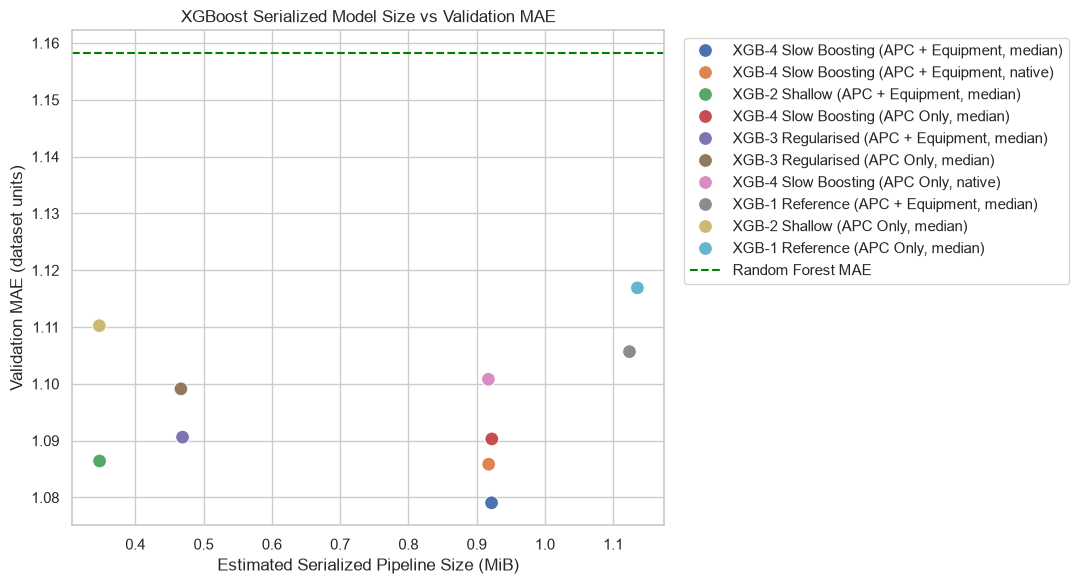

In [34]:

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=complexity_summary,
    x="Serialized Size (MiB)",
    y="MAE",
    hue="Model",
    s=100,
)

plt.axhline(
    FOREST_MAE,
    color="green",
    linestyle="--",
    label="Random Forest MAE",
)

plt.title(
    "XGBoost Serialized Model Size vs Validation MAE"
)

plt.xlabel("Estimated Serialized Pipeline Size (MiB)")
plt.ylabel("Validation MAE (dataset units)")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

## 18. Pipeline Integrity Verification

Verify transformed feature dimensions, missing-value
strategy behaviour, equipment encoding, and prediction
validity for all ten XGBoost models.

Test synthetic inputs containing unavailable
sensor readings and an unfamiliar equipment identifier.

In [35]:

for _, row in all_results_df.iterrows():

    model_name = row["Model"]

    pipeline = trained_xgb_models[model_name]

    preprocessor = pipeline.named_steps[
        "preprocessor"
    ]

    regressor = pipeline.named_steps[
        "regressor"
    ]

    transformed_names = (
        preprocessor.get_feature_names_out()
    )

    assert (
        len(transformed_names)
        == regressor.n_features_in_
    )

    assert (
        len(transformed_names)
        == len(regressor.feature_importances_)
    )

    numeric_transformer = (
        preprocessor.named_transformers_["numeric"]
    )

    if row["Missing Strategy"] == "median":

        assert (
            "imputer"
            in numeric_transformer.named_steps
        )

        assert (
            "scaler"
            not in numeric_transformer.named_steps
        )

        imputer = numeric_transformer.named_steps[
            "imputer"
        ]

        np.testing.assert_allclose(
            imputer.statistics_,
            train_df[apc_features]
            .median()
            .fillna(0)
            .to_numpy(dtype=float),
        )

    elif row["Missing Strategy"] == "native":

        assert not any(
            name.startswith(
                "numeric__missingindicator_"
            )
            for name in transformed_names
        )

        columns = feature_configurations[
            row["Configuration"]
        ]["columns"]

        transformed_sample = preprocessor.transform(
            train_df[columns]
        )

        raw_missing_mask = (
            train_df[apc_features]
            .isna()
            .to_numpy()
        )

        transformed_missing_mask = np.isnan(
            transformed_sample[
                :,
                :len(apc_features)
            ]
        )

        assert np.array_equal(
            raw_missing_mask,
            transformed_missing_mask,
        )

    equipment_present = any(
        name.startswith("equipment__")
        for name in transformed_names
    )

    assert equipment_present == (
        row["Configuration"]
        == "APC + Equipment"
    )

    predictions = validation_predictions[
        model_name
    ]

    assert np.isfinite(predictions).all()

    assert len(predictions) == len(y_val)

assert len(trained_xgb_models) == 10

print("XGBoost pipeline checks: PASSED")

print(
    "Total verified models:",
    len(trained_xgb_models)
)

XGBoost pipeline checks: PASSED
Total verified models: 10


In [36]:

equipment_candidates = eligible_results.loc[
    eligible_results["Configuration"]
    == "APC + Equipment"
]

assert not equipment_candidates.empty

best_equipment_model_name = (
    equipment_candidates
    .sort_values("MAE")
    .iloc[0]["Model"]
)

equipment_pipeline = trained_xgb_models[
    best_equipment_model_name
]

synthetic_input = (
    train_df[feature_columns]
    .iloc[[0]]
    .copy()
)

synthetic_input["equipment"] = (
    "equipment_unseen_demo"
)

missing_demo_features = apc_features[:3]

synthetic_input[missing_demo_features] = np.nan

synthetic_prediction = (
    equipment_pipeline.predict(
        synthetic_input
    )
)

assert synthetic_prediction.shape == (1,)

assert np.isfinite(
    synthetic_prediction
).all()

assert (
    synthetic_prediction > 0
).all()

print(
    "Unknown equipment and missing sensor "
    "test: PASSED"
)

print(
    "Synthetic prediction:",
    float(synthetic_prediction[0])
)

print(
    "Simulated missing features:",
    missing_demo_features
)

Unknown equipment and missing sensor test: PASSED
Synthetic prediction: 152.06637573242188
Simulated missing features: ['AMPS_TARGET_20_90_DELTA_DEP1', 'AMPS_TARGET_20_90_DEP1_M', 'AMPS_TARGET_20_90_DEP1_SPS']


## 19. Experiment Result Preservation

Preserve all XGBoost validation experiments,
hyperparameters, preprocessing strategies,
reference benchmarks and model diagnostics.

Do not export individual wafer measurements,
final test predictions or fitted model files.

In [37]:

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

results_path = (
    results_dir / "thickness_xgboost.json"
)

serializable_results = (
    all_results_df
    .astype(object)
    .where(
        pd.notna(all_results_df),
        None,
    )
    .to_dict(orient="records")
)

best_model_parameters = {
    "include_equipment": (
        best_result["Configuration"]
        == "APC + Equipment"
    ),

    "missing_strategy": str(
        best_result["Missing Strategy"]
    ),

    "n_estimators": int(
        best_result["n_estimators"]
    ),

    "max_depth": int(
        best_result["max_depth"]
    ),

    "learning_rate": float(
        best_result["learning_rate"]
    ),

    "min_child_weight": float(
        best_result["min_child_weight"]
    ),

    "reg_alpha": float(
        best_result["reg_alpha"]
    ),

    "reg_lambda": float(
        best_result["reg_lambda"]
    ),

    "subsample": SUBSAMPLE,

    "colsample_bytree": COLSAMPLE,

    "gamma": 0.0,

    "random_state": RANDOM_STATE,
}

experiment_results = {
    "project": "STRATUM",

    "experiment": "thickness_xgboost",

    "target": TARGET,

    "dataset_sha256": current_sha256,

    "evaluation_partition": "validation",

    "training_records": len(train_df),

    "validation_records": len(val_df),

    "primary_metric": "MAE",

    "reference_baseline_mae": BASELINE_MAE,

    "reference_ridge_mae": RIDGE_MAE,

    "reference_forest_mae": FOREST_MAE,

    "reference_forest_rmse": FOREST_RMSE,

    "reference_forest_r2": FOREST_R2,

    "random_state": RANDOM_STATE,

    "n_jobs": N_JOBS,

    "xgboost_version": xgboost.__version__,

    "sklearn_version": sklearn.__version__,

    "boosting_configurations": (
        boosting_configurations
    ),

    "total_experiments": len(all_results_df),

    "best_model": best_model_name,

    "best_model_parameters": (
        best_model_parameters
    ),

    "best_model_mae": float(
        best_result["MAE"]
    ),

    "best_model_rmse": float(
        best_result["RMSE"]
    ),

    "best_model_r2": float(
        best_result["R2"]
    ),

    "best_model_maximum_absolute_error": float(
        best_result["Maximum Absolute Error"]
    ),

    "best_model_non_positive_predictions": int(
        best_result["Non-Positive Predictions"]
    ),

    "best_model_improvement_vs_baseline_pct": float(
        best_result[
            "MAE Improvement vs Baseline (%)"
        ]
    ),

    "best_model_improvement_vs_forest_pct": float(
        best_result[
            "MAE Improvement vs Forest (%)"
        ]
    ),

    "error_percentiles": error_percentiles,

    "sensor_warning_bound": WARNING_BOUND,

    "sensor_warning_count": int(
        warning_error_df["Sensor Warning"].sum()
    ),

    "best_inspected_boosting_round": int(
        best_observed_round["Boosting Rounds"]
    ),

    "best_inspected_round_mae": float(
        best_observed_round["Validation MAE"]
    ),

    "results": serializable_results,

    "missing_strategy_comparison": (
        missing_comparison.to_dict(
            orient="records"
        )
    ),

    "learning_curve": (
        learning_curve_df.to_dict(
            orient="records"
        )
    ),

    "equipment_error_summary": (
        equipment_error_summary
        .reset_index()
        .to_dict(orient="records")
    ),

    "complexity_summary": (
        complexity_summary.to_dict(
            orient="records"
        )
    ),

    "warning_summary": (
        warning_summary
        .reset_index()
        .to_dict(orient="records")
    ),
}

with open(
    results_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        experiment_results,
        file,
        indent=4,
        allow_nan=False,
    )

print("XGBoost experiment results saved.")

print("ml/results/thickness_xgboost.json")

XGBoost experiment results saved.
ml/results/thickness_xgboost.json



## 20. Findings and Engineering Interpretation

### Model Development

Developed reusable XGBoost Regression pipelines
for semiconductor virtual metrology.

Evaluated:
- Eight primary boosting experiments.
- Two supplementary native missing-value experiments.
- Ten total XGBoost configurations.

### Quantitative Findings

Complete using the actual executed results:

- Best XGBoost model:
- Input configuration:
- Missing-value strategy:
- Number of boosting rounds:
- Maximum tree depth:
- Learning rate:
- Minimum child weight:
- L1 regularisation:
- L2 regularisation:
- Training MAE:
- Validation MAE:
- Validation RMSE:
- Validation R2:
- Validation MAPE:
- Prediction bias:
- Maximum absolute error:
- P95 absolute error:
- Improvement over equipment baseline:
- Improvement over bounded Ridge:
- Improvement over Random Forest:

### Missing-Value Handling

Compare native XGBoost missing-value routing
with median imputation and missingness indicators.

Record whether native missing handling improves
validation performance under matched hyperparameters.

The comparison evaluates complete preprocessing
strategies, not an isolated imputation effect.

### Equipment Metadata Ablation

Record whether explicit equipment metadata improves
predictive performance across matching experiments.

Compare the observations with the earlier
Random Forest equipment ablation.

### Generalisation and Boosting Rounds

Compare training and validation errors.

Record the observed relationship between additional
boosting rounds and chronological validation MAE.

The diagnostic learning curve does not automatically
change the selected model configuration.

### Cross-Model Performance

Compare XGBoost against:

- Equipment Mean Regressor.
- Bounded Ridge Regression.
- Random Forest Regression.

Determine whether XGBoost demonstrates measurable
predictive improvement.

### Prediction Robustness

Record:
- Non-positive prediction counts.
- Predictions outside the training target range.
- Maximum absolute error.
- Error percentiles.
- Results for the two previous Ridge failure cases.

Unlike Random Forest, XGBoost predictions are not
inherently bounded by the training target range.

### Input Distribution Diagnostics

Compare prediction errors for records with and
without standardised sensor warnings.

The current warning heuristic is not calibrated
prediction uncertainty.

### Feature Importance

Record the leading gain-based transformed features.

Compare these observations with previous regression
coefficient and Random Forest importance findings.

Importance does not establish physical causality.

### Equipment-Level Performance

Compare XGBoost and Random Forest equipment-level
MAE and signed prediction bias.

Investigate whether the systematic overprediction
previously observed for equipment_16 is reduced.

### Computational Cost

Compare training time, prediction time,
tree complexity and approximate serialized size.

Consider potential accuracy-complexity trade-offs
for deployment.

### Limitations

- Initial hyperparameter search is limited.
- Validation data is used for candidate selection.
- Native missing-value experiments use configurations
  selected through the preceding validation analysis.
- Final held-out performance remains unknown.
- Historical EDA examined the complete dataset.
- Prediction positivity does not guarantee reliability.
- Feature importance does not establish causality.
- Equipment generalisation has not been established.
- Prediction-time availability of APC variables
  requires further verification.
- Official engineering acceptance limits are unavailable.

### Conclusion

XGBoost provides a gradient-boosted nonlinear
virtual metrology approach for semiconductor
mean-thickness prediction.

Its practical value must be established through
measured predictive performance, reliability,
and computational requirements.

The next stage performs systematic model comparison
and hyperparameter optimisation before final
held-out evaluation.

### Deployment-Oriented Model Comparison

Compare the accuracy-leading XGB-4 configuration
with the compact XGB-2 configuration.

Quantify serialized size reduction, fitted tree
complexity reduction and validation performance
differences.

A smaller serialized model does not automatically
guarantee lower inference latency.

In [38]:

# Compare accuracy-leading and compact candidates

slow_model_name = (
    "XGB-4 Slow Boosting (APC + Equipment, median)"
)

shallow_model_name = (
    "XGB-2 Shallow (APC + Equipment, median)"
)

slow = complexity_summary.loc[
    complexity_summary["Model"] == slow_model_name
].iloc[0]

shallow = complexity_summary.loc[
    complexity_summary["Model"] == shallow_model_name
].iloc[0]

size_reduction_pct = (
    1
    - shallow["Serialized Size (MiB)"]
    / slow["Serialized Size (MiB)"]
) * 100

leaf_reduction_pct = (
    1
    - shallow["Total Tree Leaves"]
    / slow["Total Tree Leaves"]
) * 100

mae_penalty_pct = (
    shallow["MAE"] / slow["MAE"] - 1
) * 100

print(
    f"Serialized size reduction: "
    f"{size_reduction_pct:.6f}%"
)

print(
    f"Total leaf reduction: "
    f"{leaf_reduction_pct:.6f}%"
)

print(
    f"Validation MAE increase: "
    f"{mae_penalty_pct:.6f}%"
)

display(
    all_results_df.loc[
        all_results_df["Model"].isin([
            slow_model_name,
            shallow_model_name,
        ]),
        [
            "Model",
            "MAE",
            "RMSE",
            "R2",
            "Bias",
            "P95 Absolute Error",
            "Maximum Absolute Error",
        ],
    ].round(6)
)

Serialized size reduction: 62.280336%
Total leaf reduction: 72.112309%
Validation MAE increase: 0.681932%


,Model,MAE,RMSE,R2,Bias,P95 Absolute Error,Maximum Absolute Error
0,"XGB-4 Slow Boosting (APC + Equipment, median)",1.079062,1.456193,0.644538,-0.029205,3.093984,6.107028
2,"XGB-2 Shallow (APC + Equipment, median)",1.086421,1.456615,0.644332,-0.015663,3.069343,6.032026


### Persistent Equipment-Specific Prediction Bias

Investigate equipment_16, which exhibited systematic
overprediction in both Random Forest and XGBoost.

Compare historical training thickness distributions
with later validation measurements.

The observed distribution differences do not establish
physical equipment malfunction or manufacturing
root causes.

In [39]:

# Investigate equipment_16

equipment_id = "equipment_16"

equipment_16_train = train_df.loc[
    train_df["equipment"] == equipment_id
]

equipment_16_val = val_df.loc[
    val_df["equipment"] == equipment_id
]

equipment_16_errors = equipment_errors.loc[
    equipment_errors["equipment"] == equipment_id
]

equipment_16_summary = pd.DataFrame({
    "Training Actual": (
        equipment_16_train[TARGET].describe()
    ),

    "Validation Actual": (
        equipment_16_val[TARGET].describe()
    ),

    "Validation Predicted": (
        equipment_16_errors["Predicted"].describe()
    ),
})

display(
    equipment_16_summary.round(6)
)

print(
    "Positive signed errors:",
    int((equipment_16_errors["Bias"] > 0).sum())
)

print(
    "Negative signed errors:",
    int((equipment_16_errors["Bias"] < 0).sum())
)

print(
    "Zero signed errors:",
    int((equipment_16_errors["Bias"] == 0).sum())
)

target_mean_shift = (
    equipment_16_val[TARGET].mean()
    - equipment_16_train[TARGET].mean()
)

print(
    f"Training-to-validation actual mean shift: "
    f"{target_mean_shift:.6f}"
)

,Training Actual,Validation Actual,Validation Predicted
count,132.000000,47.000000,47.000000
mean,152.605070,149.652843,151.440414
std,2.429566,1.543258,1.204608
min,145.838724,147.103945,149.153671
25%,150.990719,148.653975,150.784981
50%,152.650309,149.377023,151.195404
75%,154.693244,150.498264,152.023361
max,157.793529,153.782798,153.974899


Positive signed errors: 47
Negative signed errors: 0
Zero signed errors: 0
Training-to-validation actual mean shift: -2.952226


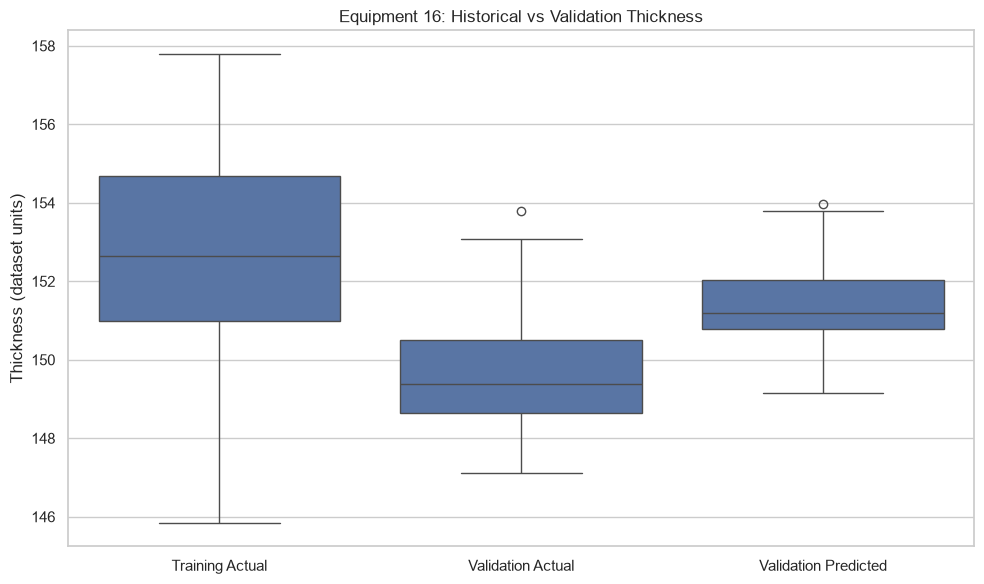

In [40]:

equipment_16_plot_data = pd.concat([
    pd.DataFrame({
        "Thickness": (
            equipment_16_train[TARGET].to_numpy()
        ),
        "Distribution": "Training Actual",
    }),

    pd.DataFrame({
        "Thickness": (
            equipment_16_val[TARGET].to_numpy()
        ),
        "Distribution": "Validation Actual",
    }),

    pd.DataFrame({
        "Thickness": (
            equipment_16_errors["Predicted"].to_numpy()
        ),
        "Distribution": "Validation Predicted",
    }),
], ignore_index=True)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=equipment_16_plot_data,
    x="Distribution",
    y="Thickness",
)

plt.title(
    "Equipment 16: Historical vs Validation Thickness"
)

plt.xlabel("")
plt.ylabel("Thickness (dataset units)")

plt.tight_layout()
plt.show()

### Paired Random Forest and XGBoost Error Comparison

Reconstruct the previously selected Random Forest
using its saved hyperparameters.

Compare absolute errors on identical validation
observations.

Assess the distribution of per-wafer improvement.

The comparison remains exploratory because both
candidates were selected using validation data.

In [41]:

from ml.random_forest_models import (
    build_random_forest_model,
)

rf_parameters = (
    forest_experiment["best_model_parameters"].copy()
)

rf_columns = (
    feature_columns
    if rf_parameters["include_equipment"]
    else apc_features
)

reference_forest = build_random_forest_model(
    numeric_features=apc_features,
    **rf_parameters,
)

reference_forest.fit(
    train_df[rf_columns],
    y_train,
)

reference_forest_predictions = (
    reference_forest.predict(
        val_df[rf_columns]
    )
)

reproduced_rf_metrics = evaluate_regression(
    y_val,
    reference_forest_predictions,
)

print(
    "Saved Random Forest MAE:",
    FOREST_MAE,
)

print(
    "Reproduced Random Forest MAE:",
    reproduced_rf_metrics["MAE"],
)

assert np.isclose(
    reproduced_rf_metrics["MAE"],
    FOREST_MAE,
    rtol=1e-6,
    atol=1e-8,
), "Random Forest reproduction mismatch."

paired_errors = pd.DataFrame({
    "lot": val_df["lot"].to_numpy(),

    "equipment": (
        val_df["equipment"].to_numpy()
    ),

    "RF Absolute Error": np.abs(
        y_val.to_numpy()
        - reference_forest_predictions
    ),

    "XGB Absolute Error": np.abs(
        y_val.to_numpy()
        - best_predictions
    ),
})

paired_errors["XGB Error Improvement"] = (
    paired_errors["RF Absolute Error"]
    - paired_errors["XGB Absolute Error"]
)

improvement = (
    paired_errors["XGB Error Improvement"]
)

tolerance = 1e-8

print(
    "XGBoost better:",
    int((improvement > tolerance).sum())
)

print(
    "Random Forest better:",
    int((improvement < -tolerance).sum())
)

print(
    "Approximately tied:",
    int((improvement.abs() <= tolerance).sum())
)

print(
    "Mean paired improvement:",
    improvement.mean()
)

print(
    "Median paired improvement:",
    improvement.median()
)

display(
    improvement.describe().round(6)
)

Saved Random Forest MAE: 1.158246551146896
Reproduced Random Forest MAE: 1.1582465511468947
XGBoost better: 464
Random Forest better: 370
Approximately tied: 0
Mean paired improvement: 0.07918417940543866
Median paired improvement: 0.05832234977798123


count    834.000000
mean       0.079184
std        0.454349
min       -1.383378
25%       -0.197857
50%        0.058322
75%        0.343800
max        1.889725
Name: XGB Error Improvement, dtype: float64

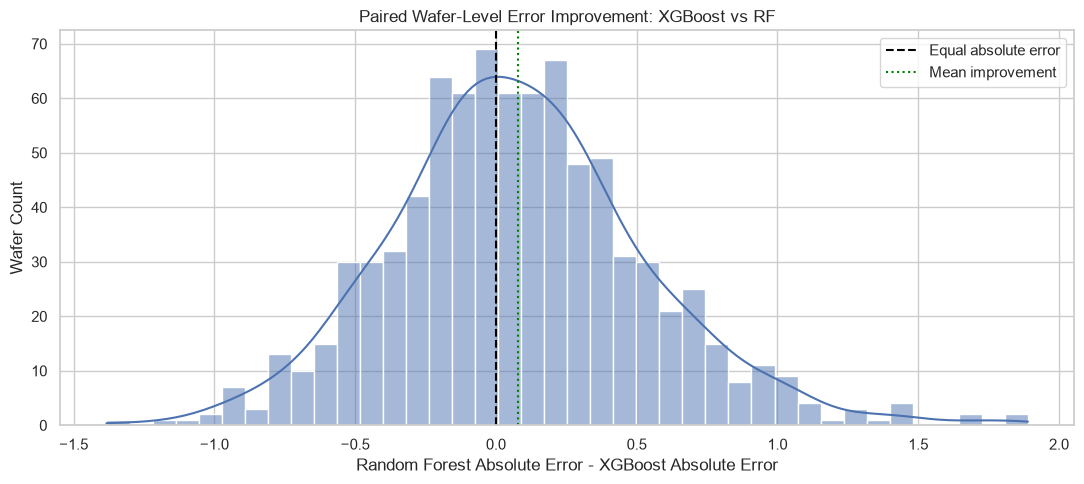

In [42]:

plt.figure(figsize=(11, 5))

sns.histplot(
    paired_errors["XGB Error Improvement"],
    bins=40,
    kde=True,
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    label="Equal absolute error",
)

plt.axvline(
    improvement.mean(),
    color="green",
    linestyle=":",
    label="Mean improvement",
)

plt.title(
    "Paired Wafer-Level Error Improvement: XGBoost vs RF"
)

plt.xlabel(
    "Random Forest Absolute Error - XGBoost Absolute Error"
)

plt.ylabel("Wafer Count")

plt.legend()
plt.tight_layout()
plt.show()


### Quantitative Findings

The best XGBoost configuration was:

- XGB-4 Slow Boosting.
- APC and equipment inputs.
- Median imputation with missingness indicators.
- Boosting rounds: 600.
- Maximum tree depth: 4.
- Learning rate: 0.025.
- Minimum child weight: 5.
- L1 regularisation: 0.1.
- L2 regularisation: 5.0.
- Subsample: 0.8.
- Column sampling: 0.8.
- Random state: 42.

Performance:

- Training MAE: 0.718159
- Training R2: 0.851459
- Validation MAE: 1.079062
- Validation RMSE: 1.456193
- Validation R2: 0.644538
- Validation MAPE: 0.710655%
- Prediction bias: -0.029205
- Generalisation gap: 0.360903
- Maximum absolute error: 6.107028
- P95 absolute error: 3.093984

Validation MAE improvements:

- Equipment mean baseline: 45.924634%
- Bounded Ridge: 14.886190%
- Random Forest: 6.836556%

All ten XGBoost configurations outperformed the
best Random Forest candidate in validation MAE,
RMSE and R2.

### Missing-Value Handling

Median imputation with explicit missingness
indicators outperformed native missing-value
routing in both matched configurations.

Native handling increased validation MAE by:

- APC Only: 0.964109%
- APC + Equipment: 0.629149%

The differences were relatively small.

The experiment compares complete preprocessing
strategies rather than an isolated imputation
effect.

### Equipment Metadata Ablation

Including explicit equipment metadata improved
validation MAE in all four matched primary
XGBoost configurations.

Improvements ranged from approximately 0.77%
to 2.14%.

The benefit was more consistent than observed
in the preceding Random Forest experiments.

### Generalisation and Boosting Rounds

The deep XGB-1 reference model achieved very low
training error but a substantial generalisation gap.

The regularised slow-boosting configuration
achieved better chronological validation performance.

Validation MAE continued decreasing through the
600th boosting round.

Further boosting-round optimisation requires
training-internal chronological validation.

### Cross-Model Performance

XGBoost achieved the strongest aggregate validation
performance among the investigated regression
families.

The selected configuration reduced MAE by
approximately 45.92% relative to the historical
equipment mean baseline.

It also reduced MAE by approximately 6.84%
relative to Random Forest.

These are model-development validation results.
Final held-out performance remains unknown.

### Prediction Robustness

All ten configurations produced finite and positive
validation predictions.

No validation predictions exceeded the historical
training target range.

The two previously problematic Ridge observations
achieved XGBoost absolute prediction errors of:

- V6G022UK04: 0.575769
- V6G01XL921: 0.532910

All 834 validation records were retained.

### Absolute Error Distribution

- Median absolute error: 0.807756
- P90 absolute error: 2.291843
- P95 absolute error: 3.093984
- P99 absolute error: 4.902625
- Maximum absolute error: 6.107028

XGBoost improved most error percentiles relative
to Random Forest, although its P95 error was
slightly higher.

These values do not represent official engineering
acceptance thresholds or calibrated intervals.

### Input Distribution Diagnostics

The exploratory sensor-warning heuristic flagged
661 of 834 validation observations.

Flagged records:

- MAE: 1.068820
- RMSE: 1.446273

Unflagged records:

- MAE: 1.118196
- RMSE: 1.493489

The flagged observations did not exhibit higher
average prediction errors.

The finding is consistent with the preceding
Random Forest diagnostic experiment.

The warning heuristic should not be interpreted
as calibrated prediction uncertainty.

### Feature Importance

Leading gain-based features included:

1. LIFE_TARGET_RUN_A
2. AMPS_TARGET_20_90_DEP1_SPS_X
3. LIFE_TARGET_DEP1_A
4. AMPS_TARGET_20_90_DEP1_SPS_M
5. missingindicator_AMPS_TARGET_RECIPE_A

Summed normalised gain importance:

- APC measurements: 71.488747%
- Equipment metadata: 10.153230%
- Missingness indicators: 18.358030%

The importance distribution suggests that
missingness patterns are useful to investigate.

Gain-based importance and Random Forest impurity
importance are different measures and must not
be treated as directly equivalent.

Neither establishes manufacturing causality.

### Equipment-Level Performance

XGBoost improved validation MAE for 13 of the
16 equipment groups.

The largest relative improvements occurred for
equipment_12, equipment_15 and equipment_8.

Systematic overprediction persisted for equipment_16:

- MAE: 1.787566
- Prediction bias: +1.787566
- Validation records: 47

Aggregate predictive improvement does not eliminate
equipment-specific weaknesses.

Further equipment-level monitoring and temporal
distribution analysis are justified.

### Computational Cost and Deployment Trade-Off

XGB-4 Slow Boosting:

- Boosting rounds: 600
- Total tree leaves: 8441
- Serialized pipeline size: 0.921866 MiB
- Validation MAE: 1.079062

XGB-2 Shallow:

- Boosting rounds: 300
- Total tree leaves: 2354
- Serialized pipeline size: 0.347725 MiB
- Validation MAE: 1.086421

The shallow configuration achieved:

- Serialized size reduction: 62.280336%
- Total leaf reduction: 72.112309%
- Validation MAE increase: 0.681932%

XGB-2 also achieved slightly lower P95 error,
maximum absolute error and absolute prediction bias.

Both configurations should remain candidates for
systematic model optimisation and deployment
selection.

Repeated inference-latency measurements are
required before establishing runtime advantages.